# Groupe 5 — Multi-label emotion detection in Darija (ary) and Algerian Arabic (arq)
BRIGHTER / SemEval-2025 Task 11 · Track A (presence, ary + arq) · Track B (intensity, arq)

**Kaggle settings:** Accelerator = GPU T4, **Internet = On** (needed for datasets).

**Protocol (as required):**
- train / dev / test per language, **val = dev**. Every decision (threshold, model choice, hyper-parameter, early stopping) is made on val.
- Anything learned (vocab, TF-IDF, fastText, scaler) is fit on **train only**.
- Test predictions are *computed and stored* with each model but **never scored before Part F**.
- Every val result is appended to `results/results.csv`.

**Map of the notebook:** 
- 0 Setup/Data Audit
- A Baselines & shortcuts 
- B Zero-shot NLI / transfer 
- C Neural from scratch 
- D Frozen PLM 
- E Fine-tuned PLM (+ multitask) 
- F Test analysis 
- G Final table.

**Deliverables written by the notebook:** `results/results.csv` · `predictions/<model>_seed<k>.csv` (id, y_true, y_pred, probabilities) · `tests/` (sanity tests).


## 0. Setup

In [1]:
!pip -q install sentencepiece gensim statsmodels 2>&1 | tail -1

In [2]:
import os, re, time, json, copy, random, math, gc, warnings, html
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from IPython.display import display, HTML
warnings.filterwarnings("ignore")

EMOS  = ["joy", "sadness", "fear", "anger", "surprise", "disgust"]
LANGS = ["ary", "arq"]
SEEDS = [42, 43, 44]
DEV   = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

PRED, MODELS, KEPT = {}, {}, {}     # prediction registry / trained small models / models kept for Part F
for _d in ["results", "predictions", "tests"]:        # deliverable layout: results/results.csv, predictions/, tests/
    os.makedirs(_d, exist_ok=True)
RES_CSV = "results/results.csv"

def log_result(part, model, lang, split, macro_f1, **extra):
    row = dict(part=part, model=model, lang=lang, split=split, macro_f1=macro_f1, extra=json.dumps(extra))
    pd.DataFrame([row]).to_csv(RES_CSV, mode="a", header=not os.path.exists(RES_CSV), index=False)

device: cuda


### Data
The cell **git-clones** the official SemEval repo (only the `semeval-2025-task11-dataset` folder; needs Internet = On).
Track A = categories, Track B = intensities, files `{split}/{lang}.csv`. If the clone fails it looks for an uploaded copy under
`/kaggle/input`, then falls back to HuggingFace.

**The cell checks whether test labels exist.** If not, fallback protocol from the assignment: dev becomes the sealed test, val = 10 % of train.

In [3]:
DATASET_CAT = "brighter-dataset/BRIGHTER-emotion-categories"
DATASET_INT = "brighter-dataset/BRIGHTER-emotion-intensities"

# Official SemEval GitHub files (task-dataset/semeval-2025-task11-dataset/track_a|track_b/{train,dev,test}/{lang}.csv).
# Upload that folder as a Kaggle dataset; it is found automatically under /kaggle/input. Or set DATA_ROOT by hand.
import glob, subprocess
REL = "task-dataset/semeval-2025-task11-dataset"
CLONE = "SemEval2025-Task11"
if not os.path.isdir(f"{CLONE}/{REL}/track_a"):            # git clone (only the dataset folder), needs Internet = On
    subprocess.run(f"rm -rf {CLONE} && git clone -q --depth 1 --filter=blob:none --sparse "
                   f"https://github.com/emotion-analysis-project/SemEval2025-Task11.git {CLONE} && "
                   f"cd {CLONE} && git sparse-checkout set {REL}", shell=True)
DATA_ROOT = f"{CLONE}/{REL}" if os.path.isdir(f"{CLONE}/{REL}/track_a") else None
if DATA_ROOT is None:                                       # fallback: a copy uploaded as a Kaggle dataset
    hits = glob.glob("/kaggle/input/**/track_a", recursive=True)
    DATA_ROOT = os.path.dirname(hits[0]) if hits else None
print("DATA_ROOT =", DATA_ROOT)

def read_track(track, lang):
    return {s: pd.read_csv(f"{DATA_ROOT}/{track}/{s}/{lang}.csv") for s in ["train", "dev", "test"]}

def load_lang(lang):
    if DATA_ROOT:
        return read_track("track_a", lang)
    from datasets import load_dataset
    ds = load_dataset(DATASET_CAT, lang)
    return {k: ds[k].to_pandas() for k in ds.keys()}

RAW = {l: load_lang(l) for l in LANGS}
for l in LANGS:
    for k, v in RAW[l].items():
        print(l, k, v.shape, list(v.columns)[:9])

DATA_ROOT = SemEval2025-Task11/task-dataset/semeval-2025-task11-dataset
ary train (1608, 8) ['id', 'text', 'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
ary dev (267, 8) ['id', 'text', 'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
ary test (812, 8) ['id', 'text', 'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
arq train (901, 8) ['id', 'text', 'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
arq dev (100, 8) ['id', 'text', 'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
arq test (902, 8) ['id', 'text', 'anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


In [4]:
from sklearn.model_selection import train_test_split
def has_labels(df):
    return all(e in df.columns for e in EMOS) and df[EMOS].notna().all().all() and df[EMOS].values.sum() > 0

Y = lambda df: df[EMOS].values.astype(int)
OFFICIAL = {"ary": dict(train=1608, dev=267, test=812), "arq": dict(train=901, dev=100, test=902)}   # sizes given in the assignment
SPLIT = {}
for l in LANGS:
    # the HF viewer lists dev/test counts ~2x the official sizes -> drop rows with a repeated id, then compare with the official sizes
    r = {k: (v.drop_duplicates(subset="id") if "id" in v.columns else v).reset_index(drop=True) for k, v in RAW[l].items()}
    print(l, "rows before/after id-dedup:", {k: (len(RAW[l][k]), len(r[k])) for k in r}, "| official:", OFFICIAL[l])
    if has_labels(r["test"]):
        SPLIT[l] = dict(train=r["train"], val=r["dev"], test=r["test"]); proto = "official (val = dev)"
    else:
        tr, va = train_test_split(r["train"], test_size=0.1, random_state=0)
        SPLIT[l] = dict(train=tr.reset_index(drop=True), val=va.reset_index(drop=True), test=r["dev"]); proto = "FALLBACK (test = dev, val = 10% train)"
    for k in ["train", "val", "test"]:
        SPLIT[l][k] = SPLIT[l][k].copy()
        SPLIT[l][k][EMOS] = SPLIT[l][k][EMOS].astype(int)
        SPLIT[l][k]["lang"] = l
    print(l, proto, {k: len(v) for k, v in SPLIT[l].items()})

ary rows before/after id-dedup: {'train': (1608, 1608), 'dev': (267, 267), 'test': (812, 812)} | official: {'train': 1608, 'dev': 267, 'test': 812}
ary official (val = dev) {'train': 1608, 'val': 267, 'test': 812}
arq rows before/after id-dedup: {'train': (901, 901), 'dev': (100, 100), 'test': (902, 902)} | official: {'train': 901, 'dev': 100, 'test': 902}
arq official (val = dev) {'train': 901, 'val': 100, 'test': 902}


### Metrics, thresholds, registry

In [5]:
def col_f1(y, pred):
    """per-column F1 (zero_division=0). y, pred: (n,k) int arrays."""
    y = y.astype(int); pred = pred.astype(int)
    tp = (y & pred).sum(0); fp = ((1 - y) & pred).sum(0); fn = (y & (1 - pred)).sum(0)
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)

GRID = np.arange(0.05, 0.951, 0.05)
def tune_thr(y, p, per_label=True):
    sc = np.stack([col_f1(y, (p >= t).astype(int)) for t in GRID])      # (G,k)
    if per_label: return GRID[sc.argmax(0)]
    return np.full(y.shape[1], GRID[sc.mean(1).argmax()])
decide = lambda p, thr: (p >= thr).astype(int)

def finish(part, model, lang, pv, pt, per_label=True, **meta):
    """thresholds tuned on val; register val+test probs (test stays sealed until Part F); return val macro-F1"""
    yv = Y(SPLIT[lang]["val"]); thr = tune_thr(yv, pv, per_label)
    f = float(col_f1(yv, decide(pv, thr)).mean())
    PRED.setdefault(model, {}).setdefault(lang, []).append(dict(val=pv, test=pt, thr=thr, val_f1=f, **meta))
    return f

def val_score(model, lang): return float(np.mean([i["val_f1"] for i in PRED[model][lang]]))

def log_group(part, model, lang):
    it = PRED[model][lang]; v = [i["val_f1"] for i in it]
    ex = {k: float(np.mean([i[k] for i in it])) for k, x in it[0].items()
          if isinstance(x, (int, float, np.floating)) and k != "val_f1"}
    log_result(part, model, lang, "val", float(np.mean(v)), std=float(np.std(v)), n_seeds=len(v), **ex)

def summary():
    rows = [dict(model=m, lang=l, val_f1=val_score(m, l)) for m, d in PRED.items() for l in d]
    t = pd.DataFrame(rows).pivot(index="model", columns="lang", values="val_f1")
    return t.assign(mean=t.mean(1)).sort_values("mean", ascending=False).round(4)

## 4.1 Audit
First the text normalisation and cue detectors (used everywhere), then the audit tables.

In [6]:
ARAB  = re.compile(r"[\u0600-\u06FF]")
LATIN = re.compile(r"[A-Za-z]")
EMOJI = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\u2B50\u2764\uFE0F\u200d]")
LAUGH_RE  = re.compile(r"(?:ه{3,}|(?:هه){2,}|(?:ha){2,}|(?:ah){2,}|h{3,}|\bmdr\b|\bptdr\b|\blol\b|\bxd+\b)", re.I)
LAUGH_EMO = set("😂🤣😹😆")
CRY_EMO   = set("😭😢😿😥😞")
TASHKEEL  = re.compile("[\u064B-\u0652\u0670\u0640]")
URL  = re.compile(r"https?://\S+|www\.\S+")
MENT = re.compile(r"@?<username>|@\w+")      # the ary data contains the literal placeholder "@<username>" (215 times)
FR_WORDS = set("je tu il elle nous vous ils le la les un une des est pas mais pour avec que qui dans sur ça c'est très bien merci mdr trop rien comme quoi aussi ce cette mon ma mes".split())

def norm_text(t, strip_emoji=False, squeeze=True, strip_laugh=False, unify=True, space_emoji=True):
    t = URL.sub(" <url> ", str(t)); t = MENT.sub(" <user> ", t)
    t = TASHKEEL.sub("", t)
    if unify: t = re.sub("[إأآ]", "ا", t).replace("ى", "ي").replace("ة", "ه")
    t = t.lower()
    if strip_laugh:
        t = LAUGH_RE.sub(" ", t); t = "".join(c for c in t if c not in LAUGH_EMO)
    if strip_emoji: t = EMOJI.sub(" ", t)
    elif space_emoji: t = EMOJI.sub(lambda m: " " + m.group() + " ", t)
    if squeeze: t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip()

def strip_cues(t):
    t = LAUGH_RE.sub(" ", t); t = "".join(c for c in t if c not in LAUGH_EMO)
    return re.sub(r"\s+", " ", EMOJI.sub(" ", t)).strip() or "."

def script_of(t):
    a, l = bool(ARAB.search(t)), bool(LATIN.search(t))
    return "arabic" if a and not l else "latin" if l and not a else "mixed" if a and l else "other"

def feats(df):
    t = df.text
    return pd.DataFrame({
        "script": t.map(script_of),
        "emoji": t.map(lambda s: bool(EMOJI.search(s))),
        "laugh_txt": t.map(lambda s: bool(LAUGH_RE.search(s))),
        "laugh_emo": t.map(lambda s: any(c in LAUGH_EMO for c in s)),
        "cry_emo": t.map(lambda s: any(c in CRY_EMO for c in s)),
        "french": t.map(lambda s: any(w in FR_WORDS for w in re.findall(r"[a-zçéèêàùô']+", s.lower()))),
        "repeat_letters": t.map(lambda s: bool(re.search(r"(.)\1{2,}", s))),
        "punct_!?": t.map(lambda s: any(c in s for c in "!?؟")),
        "n_words": t.str.split().str.len(),
        "n_emo": Y(df).sum(1)})

rows = []
for l in LANGS:
    for s in ["train", "val", "test"]:
        f = feats(SPLIT[l][s])
        rows.append(dict(lang=l, split=s, n=len(f), arabic=(f.script == "arabic").mean(), latin=(f.script == "latin").mean(),
                         mixed=(f.script == "mixed").mean(), emoji=f.emoji.mean(), laugh_txt=f.laugh_txt.mean(),
                         french=f.french.mean(), repeat_letters=f.repeat_letters.mean(), mean_words=f.n_words.mean()))
display(pd.DataFrame(rows).round(3))

,lang,split,n,arabic,latin,mixed,emoji,laugh_txt,french,repeat_letters,mean_words
0,ary,train,1608,0.817,0.174,0.010,0.029,0.030,0.056,0.088,13.053
1,ary,val,267,0.779,0.199,0.022,0.030,0.045,0.045,0.079,12.899
2,ary,test,812,0.821,0.167,0.011,0.034,0.026,0.054,0.071,13.005
3,arq,train,901,0.999,0.000,0.001,0.000,0.000,0.001,0.042,14.333
4,arq,val,100,1.000,0.000,0.000,0.000,0.000,0.000,0.000,14.660
5,arq,test,902,0.993,0.000,0.007,0.000,0.000,0.002,0.022,14.402


In [7]:
# duplicates: exact + normalised, inside train and train<->val/test
def dup_audit(l):
    tr, va, te = SPLIT[l]["train"], SPLIT[l]["val"], SPLIT[l]["test"]; rows = []
    for nm, fn in [("exact", lambda s: s), ("normalised", norm_text)]:
        k = tr.text.map(fn); g = pd.DataFrame({"k": k, "lab": [tuple(x) for x in Y(tr)]})
        rows.append(dict(lang=l, key=nm, train_dup_rows=int(g.k.duplicated(keep=False).sum()),
                         contradictory_groups=int((g.groupby("k").lab.nunique() > 1).sum()),
                         test_texts_in_train=int(te.text.map(fn).isin(set(k)).sum()),
                         val_texts_in_train=int(va.text.map(fn).isin(set(k)).sum())))
    return rows
display(pd.DataFrame([r for l in LANGS for r in dup_audit(l)]))

# POLICY: in train only -> keep one copy of identical (normalised text, labels); drop groups whose duplicates have
# contradictory labels (no consistent signal). Val/test are never modified; train∩test overlap is reported (leakage check in Part F).
for l in LANGS:
    tr = SPLIT[l]["train"]; SPLIT[l]["train_raw"] = tr
    g = pd.DataFrame({"k": tr.text.map(norm_text), "lab": [tuple(x) for x in Y(tr)]})
    bad = set(g.groupby("k").lab.nunique().loc[lambda s: s > 1].index)
    keep = (~g.k.isin(bad)) & (~g.k.duplicated(keep="first"))
    SPLIT[l]["train"] = tr[keep.values].reset_index(drop=True)
    print(l, "train", len(tr), "->", len(SPLIT[l]["train"]))

,lang,key,train_dup_rows,contradictory_groups,test_texts_in_train,val_texts_in_train
0,ary,exact,0,0,0,0
1,ary,normalised,0,0,0,0
2,arq,exact,2,0,0,0
3,arq,normalised,2,0,1,0


ary train 1608 -> 1608
arq train 901 -> 900


In [8]:
# number of emotions per text + label cues
for l in LANGS:
    print(l, "- share of texts by number of emotions")
    display(pd.DataFrame({s: pd.Series(Y(SPLIT[l][s]).sum(1)).value_counts(normalize=True).sort_index()
                          for s in ["train", "val", "test"]}).round(3))

ary - share of texts by number of emotions


,train,val,test
0,0.282,0.285,0.280
1,0.607,0.607,0.601
2,0.098,0.097,0.100
3,0.009,0.007,0.012
4,0.004,0.004,0.007


arq - share of texts by number of emotions


,train,val,test
0,0.101,0.12,0.103
1,0.326,0.32,0.345
2,0.337,0.36,0.317
3,0.178,0.15,0.172
4,0.056,0.04,0.059
5,0.003,0.01,0.003
6,NaN,NaN,0.001


## Part A — Label distribution, trivial classifiers, TF-IDF baseline, shortcuts
Metric retained: **macro-F1 over the 6 emotions** (answer for Q1: the classes are very imbalanced and multi-label, accuracy/micro-F1 are dominated by the
frequent labels and by the "no emotion" case; macro-F1 gives each emotion the same weight).

In [9]:
def dist_table():
    rows = []
    for l in LANGS + ["ALL"]:
        for s in ["train", "val", "test"]:
            d = SPLIT[l][s] if l != "ALL" else pd.concat([SPLIT[x][s] for x in LANGS])
            r = dict(lang=l, split=s, n=len(d)); r.update({e: int(d[e].sum()) for e in EMOS}); r["none"] = int((Y(d).sum(1) == 0).sum()); rows.append(r)
    t = pd.DataFrame(rows)
    pct = t.copy(); pct[EMOS + ["none"]] = (t[EMOS + ["none"]].div(t.n, axis=0) * 100).round(1)
    return t, pct
counts, pct = dist_table()
display(counts); display(pct)

def trivial(l, split="val"):
    y = Y(SPLIT[l][split]); top = Y(SPLIT[l]["train"]).mean(0).argmax()
    p1 = np.zeros_like(y); p1[:, top] = 1
    return dict(lang=l, split=split, none_macroF1=col_f1(y, np.zeros_like(y)).mean(), most_freq_emotion=EMOS[top],
                most_freq_macroF1=col_f1(y, p1).mean(), predict_all_macroF1=col_f1(y, np.ones_like(y)).mean())
tt = pd.DataFrame([trivial(l) for l in LANGS]); display(tt.round(4))
for r in tt.to_dict("records"):
    log_result("A", "trivial_none", r["lang"], "val", r["none_macroF1"]); log_result("A", "trivial_most_freq", r["lang"], "val", r["most_freq_macroF1"])

,lang,split,n,joy,sadness,fear,anger,surprise,disgust,none
0,ary,train,1608,302,246,119,380,246,66,454
1,ary,val,267,50,41,20,63,39,11,76
2,ary,test,812,152,128,63,193,129,39,227
3,arq,train,900,153,403,223,296,313,206,91
4,arq,val,100,13,40,26,31,32,28,12
5,arq,test,902,160,405,216,293,305,202,93
6,ALL,train,2508,455,649,342,676,559,272,545
7,ALL,val,367,63,81,46,94,71,39,88
8,ALL,test,1714,312,533,279,486,434,241,320


,lang,split,n,joy,sadness,fear,anger,surprise,disgust,none
0,ary,train,1608,18.8,15.3,7.4,23.6,15.3,4.1,28.2
1,ary,val,267,18.7,15.4,7.5,23.6,14.6,4.1,28.5
2,ary,test,812,18.7,15.8,7.8,23.8,15.9,4.8,28.0
3,arq,train,900,17.0,44.8,24.8,32.9,34.8,22.9,10.1
4,arq,val,100,13.0,40.0,26.0,31.0,32.0,28.0,12.0
5,arq,test,902,17.7,44.9,23.9,32.5,33.8,22.4,10.3
6,ALL,train,2508,18.1,25.9,13.6,27.0,22.3,10.8,21.7
7,ALL,val,367,17.2,22.1,12.5,25.6,19.3,10.6,24.0
8,ALL,test,1714,18.2,31.1,16.3,28.4,25.3,14.1,18.7


,lang,split,none_macroF1,most_freq_emotion,most_freq_macroF1,predict_all_macroF1
0,ary,val,0.0,anger,0.0636,0.2395
1,arq,val,0.0,sadness,0.0952,0.4350


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

def run_tfidf(l, prep=norm_text, cw="balanced", C=4.0, tr=None):
    tr = SPLIT[l]["train"] if tr is None else tr
    Xtr = [prep(t) for t in tr.text]
    vec = FeatureUnion([("w", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, token_pattern=r"\S+")),
                        ("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True))]).fit(Xtr)
    clf = OneVsRestClassifier(LogisticRegression(C=C, class_weight=cw, max_iter=3000)).fit(vec.transform(Xtr), Y(tr))
    f = lambda texts: clf.predict_proba(vec.transform([prep(t) for t in texts]))
    return f, clf, vec

val_f1_from = lambda l, pv, per_label=True: float(col_f1(Y(SPLIT[l]["val"]), decide(pv, tune_thr(Y(SPLIT[l]["val"]), pv, per_label))).mean())

for l in LANGS:
    t0 = time.time(); f, clf, vec = run_tfidf(l); tt_ = time.time() - t0
    pv, pt = f(SPLIT[l]["val"].text.tolist()), f(SPLIT[l]["test"].text.tolist())
    sc = finish("A", "A_tfidf_lr", l, pv, pt, train_time=tt_, params=sum(e.coef_.size for e in clf.estimators_ if hasattr(e, "coef_")))
    KEPT[("A_tfidf_lr", l)] = dict(infer=f); log_group("A", "A_tfidf_lr", l)
    print(l, "TF-IDF + OvR-LR  val macro-F1 =", round(sc, 4))

ary TF-IDF + OvR-LR  val macro-F1 = 0.4492
arq TF-IDF + OvR-LR  val macro-F1 = 0.5918


In [11]:
# Q6 (part 1): single vs per-label threshold, class weighting  -> TF-IDF
rows = []
for l in LANGS:
    for cw in [None, "balanced"]:
        f, _, _ = run_tfidf(l, cw=cw); pv = f(SPLIT[l]["val"].text.tolist()); yv = Y(SPLIT[l]["val"])
        rows.append(dict(lang=l, class_weight=str(cw), thr_0_5=col_f1(yv, decide(pv, 0.5)).mean(),
                         single_thr=val_f1_from(l, pv, False), per_label_thr=val_f1_from(l, pv, True)))
display(pd.DataFrame(rows).round(4))

# per-emotion F1 + number of training positives (which labels stay weak?)
for l in LANGS:
    it = PRED["A_tfidf_lr"][l][0]; yv = Y(SPLIT[l]["val"])
    display(pd.DataFrame({"F1_val": col_f1(yv, decide(it["val"], it["thr"])), "thr": it["thr"],
                          "train_pos": Y(SPLIT[l]["train"]).sum(0), "val_pos": yv.sum(0)}, index=EMOS).round(3).rename_axis(l))

,lang,class_weight,thr_0_5,single_thr,per_label_thr
0,ary,None,0.1570,0.3786,0.4191
1,ary,balanced,0.3319,0.4251,0.4492
2,arq,None,0.3727,0.5376,0.5804
3,arq,balanced,0.4967,0.5520,0.5918


,F1_val,thr,train_pos,val_pos
ary,,,,
joy,0.527,0.25,302,50
sadness,0.547,0.35,246,41
fear,0.424,0.20,119,20
anger,0.517,0.30,380,63
surprise,0.444,0.45,246,39
disgust,0.235,0.30,66,11


,F1_val,thr,train_pos,val_pos
arq,,,,
joy,0.545,0.50,153,13
sadness,0.630,0.35,403,40
fear,0.621,0.40,223,26
anger,0.602,0.25,296,31
surprise,0.641,0.40,313,32
disgust,0.512,0.20,206,28


In [12]:
# Q3: preprocessing ablation (TF-IDF, val macro-F1)
VARIANTS = {
    "raw text":                lambda s: s,
    "lower only":              lambda s: s.lower(),
    "norm (default)":          norm_text,
    "norm, no emojis":         lambda s: norm_text(s, strip_emoji=True),
    "norm, no laughter":       lambda s: norm_text(s, strip_laugh=True),
    "norm, no emoji+laugh":    lambda s: norm_text(s, strip_emoji=True, strip_laugh=True),
    "norm, keep letter repeats": lambda s: norm_text(s, squeeze=False),
    "norm, no letter unification": lambda s: norm_text(s, unify=False),
    "norm, drop latin/arabizi tokens": lambda s: re.sub(r"\s+", " ", re.sub(r"[a-z0-9]+", " ", norm_text(s))).strip(),   # arabizi ablation (ary only has any)
}
rows = []
for name, fn in VARIANTS.items():
    r = dict(variant=name)
    for l in LANGS:
        f, _, _ = run_tfidf(l, prep=fn); r[l] = val_f1_from(l, f(SPLIT[l]["val"].text.tolist()))
    rows.append(r)
abl = pd.DataFrame(rows).set_index("variant"); abl["mean"] = abl.mean(1); display(abl.round(4))
for n, r in abl.iterrows():
    for l in LANGS: log_result("A-ablation", n, l, "val", float(r[l]))

,ary,arq,mean
variant,,,
raw text,0.4436,0.5895,0.5165
lower only,0.4436,0.5895,0.5165
norm (default),0.4492,0.5918,0.5205
"norm, no emojis",0.4451,0.5918,0.5184
"norm, no laughter",0.4463,0.5918,0.5191
"norm, no emoji+laugh",0.4456,0.5918,0.5187
"norm, keep letter repeats",0.4467,0.5928,0.5197
"norm, no letter unification",0.4484,0.5994,0.5239
"norm, drop latin/arabizi tokens",0.4230,0.5918,0.5074


In [13]:
# Q2: surface cues vs labels, one-rule classifiers
FT = {l: feats(SPLIT[l]["train"]) for l in LANGS}
for l in LANGS:
    bcols = ["emoji", "laugh_txt", "laugh_emo", "cry_emo", "french", "repeat_letters", "punct_!?"]
    X = FT[l][bcols].astype(float).assign(latin=(FT[l].script == "latin").astype(float), long=(FT[l].n_words > FT[l].n_words.median()).astype(float))
    c = pd.concat([X, pd.DataFrame(Y(SPLIT[l]["train"]), columns=EMOS)], axis=1).corr().loc[X.columns, EMOS]
    print(l, "(phi correlation of cue with label, train)"); display(c.round(2))

def rule_pred(df):
    p = np.zeros((len(df), 6), int)
    la = df.text.map(lambda s: any(c in LAUGH_EMO for c in s)).values
    cr = df.text.map(lambda s: any(c in CRY_EMO for c in s)).values
    p[la, EMOS.index("joy")] = 1; p[cr, EMOS.index("sadness")] = 1
    return p, la.mean(), cr.mean()
for l in LANGS:
    yv = Y(SPLIT[l]["val"]); p, cl, cc = rule_pred(SPLIT[l]["val"]); f = col_f1(yv, p)
    print(l, "rule macro-F1 =", round(f.mean(), 4), "| F1 joy =", round(f[0], 3), "| F1 sadness =", round(f[1], 3),
          "| coverage laugh-emoji = %.3f, cry-emoji = %.3f" % (cl, cc))
    log_result("A", "rule_emoji", l, "val", float(f.mean()))

ary (phi correlation of cue with label, train)


,joy,sadness,fear,anger,surprise,disgust
emoji,0.22,-0.02,-0.03,-0.06,-0.05,0.00
laugh_txt,0.12,-0.06,-0.05,0.00,-0.08,0.02
laugh_emo,0.18,-0.04,-0.03,-0.03,-0.04,0.01
cry_emo,0.02,0.08,-0.02,-0.04,-0.03,-0.01
french,0.07,-0.08,-0.05,0.01,-0.09,0.00
repeat_letters,0.15,-0.03,-0.08,0.07,-0.10,0.02
punct_!?,-0.09,-0.03,-0.04,0.12,0.03,0.01
latin,0.15,-0.14,-0.11,0.00,-0.15,0.01
long,-0.09,-0.01,0.02,0.19,0.00,0.01


arq (phi correlation of cue with label, train)


,joy,sadness,fear,anger,surprise,disgust
emoji,NaN,NaN,NaN,NaN,NaN,NaN
laugh_txt,NaN,NaN,NaN,NaN,NaN,NaN
laugh_emo,NaN,NaN,NaN,NaN,NaN,NaN
cry_emo,NaN,NaN,NaN,NaN,NaN,NaN
french,-0.02,-0.03,-0.02,0.05,-0.02,0.06
repeat_letters,-0.01,0.10,0.07,-0.02,0.02,-0.01
punct_!?,-0.05,-0.07,0.03,0.30,0.32,0.17
latin,NaN,NaN,NaN,NaN,NaN,NaN
long,0.07,0.20,0.08,-0.04,0.05,0.08


ary rule macro-F1 = 0.0079 | F1 joy = 0.0 | F1 sadness = 0.048 | coverage laugh-emoji = 0.004, cry-emoji = 0.004
arq rule macro-F1 = 0.0 | F1 joy = 0.0 | F1 sadness = 0.0 | coverage laugh-emoji = 0.000, cry-emoji = 0.000


### Shortcut audit — repeated tokens, templates, mentions
Some texts share artefacts that are not emotional content: `@username` mentions, source markers or templates (e.g. `عيني:`, `الراوي:`), repeated openings.
A model can score well by memorising them. Below: (1) which frequent tokens / openings are strongly tied to one label, (2) whether they also occur in val/test
(a shortcut only helps if it transfers), (3) an ablation that deletes them and re-scores TF-IDF on val.
Mentions are turned into `<user>` / `<url>` by `norm_text` (kept as a token, so they ARE visible to the TF-IDF / C models); the pre-trained models (`plm_prep`) already delete them.

In [14]:
TOK_A = re.compile(r"<\w+>|\w+|[^\w\s]")
toks_a = lambda t: TOK_A.findall(norm_text(t))

def token_table(l, min_df=8):
    tr = SPLIT[l]["train"]; y = Y(tr); base = y.mean(0); n = len(tr)
    docs = [set(toks_a(t)) for t in tr.text]
    df = Counter(w for d in docs for w in d)
    dv = Counter(w for t in SPLIT[l]["val"].text for w in set(toks_a(t)))
    dt = Counter(w for t in SPLIT[l]["test"].text for w in set(toks_a(t)))
    rows = []
    for w, c in df.items():
        if c < min_df: continue
        idx = [i for i, d in enumerate(docs) if w in d]; prec = y[idx].mean(0); lift = prec / np.maximum(base, 1e-9)
        j = int(np.argmax(prec * (c >= min_df)))                     # emotion this token is most associated with
        rows.append(dict(token=w, train_df=c, train_pct=100 * c / n, val_pct=100 * dv[w] / len(SPLIT[l]["val"]), test_pct=100 * dt[w] / len(SPLIT[l]["test"]),
                         top_emotion=EMOS[j], P_emotion_given_token=prec[j], base_rate=base[j], lift=lift[j],
                         none_rate=float((y[idx].sum(1) == 0).mean())))
    return pd.DataFrame(rows)

TT = {l: token_table(l) for l in LANGS}
for l in LANGS:
    t = TT[l]
    print(f"{l}: most frequent tokens (are they emotional words or artefacts?)")
    display(t.sort_values("train_df", ascending=False).head(15).round(3))
    print(f"{l}: strongest single-token label predictors (train_df >= 8, sorted by precision then frequency)")
    display(t[t.P_emotion_given_token >= 0.7].sort_values(["P_emotion_given_token", "train_df"], ascending=False).head(15).round(3))
    print(f"{l}: <user> / <url> / manual suspects")
    display(t[t.token.isin(["<user>", "<url>", "عيني", "الراوي", ":"])].round(3))

ary: most frequent tokens (are they emotional words or artefacts?)


,token,train_df,train_pct,val_pct,test_pct,top_emotion,P_emotion_given_token,base_rate,lift,none_rate
8,.,487,30.286,34.082,32.635,anger,0.265,0.236,1.121,0.234
2,من,259,16.107,17.228,14.655,anger,0.259,0.236,1.095,0.263
25,علي,237,14.739,17.228,12.808,anger,0.270,0.236,1.143,0.308
1,في,212,13.184,11.610,14.778,anger,0.269,0.236,1.138,0.259
9,:,201,12.500,10.487,11.330,anger,0.214,0.236,0.905,0.408
33,',189,11.754,10.487,14.409,joy,0.402,0.188,2.141,0.116
74,",",107,6.654,6.367,4.680,surprise,0.206,0.153,1.344,0.383
14,ديال,99,6.157,3.745,6.897,surprise,0.384,0.153,2.509,0.152
45,و,93,5.784,4.869,6.034,anger,0.323,0.236,1.365,0.194
62,”,88,5.473,5.618,4.803,anger,0.250,0.236,1.058,0.273


ary: strongest single-token label predictors (train_df >= 8, sorted by precision then frequency)


,token,train_df,train_pct,val_pct,test_pct,top_emotion,P_emotion_given_token,base_rate,lift,none_rate
201,شكرا,10,0.622,0.000,0.493,joy,0.900,0.188,4.792,0.000
199,فكري,19,1.182,2.247,1.355,sadness,0.895,0.153,5.849,0.053
256,حد,8,0.498,0.000,0.369,anger,0.875,0.236,3.703,0.000
68,😂,15,0.933,0.000,0.493,joy,0.867,0.188,4.615,0.000
121,كيران,11,0.684,0.000,0.493,anger,0.818,0.236,3.462,0.000
200,محسن,18,1.119,2.247,1.232,sadness,0.778,0.153,5.084,0.111
203,تحيه,9,0.560,0.000,0.369,joy,0.778,0.188,4.141,0.000
254,wa,12,0.746,1.498,0.616,joy,0.750,0.188,3.993,0.083
194,قتل,8,0.498,0.000,0.862,sadness,0.750,0.153,4.902,0.250
228,وفاه,8,0.498,0.375,0.493,sadness,0.750,0.153,4.902,0.000


ary: <user> / <url> / manual suspects


,token,train_df,train_pct,val_pct,test_pct,top_emotion,P_emotion_given_token,base_rate,lift,none_rate
9,:,201,12.500,10.487,11.330,anger,0.214,0.236,0.905,0.408
10,<user>,80,4.975,7.116,4.803,joy,0.375,0.188,1.997,0.262


... (2 outputs left out)

arq: strongest single-token label predictors (train_df >= 8, sorted by precision then frequency)


,token,train_df,train_pct,val_pct,test_pct,top_emotion,P_emotion_given_token,base_rate,lift,none_rate
99,منصوريه,11,1.222,3.0,1.774,sadness,1.000,0.448,2.233,0.000
206,رجليه,10,1.111,1.0,0.111,sadness,1.000,0.448,2.233,0.000
124,الحرب,9,1.000,2.0,0.887,fear,1.000,0.248,4.036,0.000
174,منون,9,1.000,0.0,0.665,sadness,1.000,0.448,2.233,0.000
217,جاره,10,1.111,0.0,0.222,anger,0.900,0.329,2.736,0.000
205,شغل,9,1.000,1.0,0.998,sadness,0.889,0.448,1.985,0.000
193,ضربه,8,0.889,2.0,0.554,surprise,0.875,0.348,2.516,0.000
211,عيطت,8,0.889,0.0,0.665,anger,0.875,0.329,2.660,0.000
225,مسكينه,8,0.889,1.0,0.665,sadness,0.875,0.448,1.954,0.000
250,فاطيمه,8,0.889,1.0,0.776,sadness,0.875,0.448,1.954,0.000


arq: <user> / <url> / manual suspects


,token,train_df,train_pct,val_pct,test_pct,top_emotion,P_emotion_given_token,base_rate,lift,none_rate
0,عيني,213,23.667,23.0,19.956,sadness,0.516,0.448,1.153,0.066
6,:,811,90.111,89.0,90.244,sadness,0.436,0.448,0.975,0.101
15,الراوي,431,47.889,51.0,47.450,sadness,0.420,0.448,0.938,0.148


In [15]:
# repeated openings / endings (template detector): same first 2 tokens or same last token in many texts
for l in LANGS:
    tr = SPLIT[l]["train"]; y = Y(tr); T = [toks_a(t) for t in tr.text]
    for nm, key in [("first-2 tokens", lambda w: " ".join(w[:2]) if len(w) >= 2 else None), ("last token", lambda w: w[-1] if w else None)]:
        c = Counter(k for w in T if (k := key(w)) is not None); rows = []
        for k, n_ in c.most_common(40):
            if n_ < 6: break
            idx = [i for i, w in enumerate(T) if key(w) == k]; prec = y[idx].mean(0); j = int(prec.argmax())
            rows.append(dict(pattern=k, n=n_, top_emotion=EMOS[j], precision=prec[j], base_rate=y.mean(0)[j], none_rate=float((y[idx].sum(1) == 0).mean())))
        print(f"{l}: repeated {nm}"); display(pd.DataFrame(rows).head(10).round(3))

ary: repeated first-2 tokens


,pattern,n,top_emotion,precision,base_rate,none_rate
0,<user> <user>,26,anger,0.385,0.236,0.269
1,عاجل .,16,surprise,0.375,0.153,0.250
2,خاص .,10,sadness,0.200,0.153,0.600
3,بالفيديو .,9,fear,0.333,0.074,0.000


ary: repeated last token


,pattern,n,top_emotion,precision,base_rate,none_rate
0,',186,joy,0.403,0.188,0.118
1,",",97,surprise,0.216,0.153,0.402
2,.,24,anger,0.375,0.236,0.292
3,!,17,surprise,0.471,0.153,0.176
4,),16,surprise,0.312,0.153,0.188
5,فيديو,16,surprise,0.375,0.153,0.375
6,hh,14,joy,0.429,0.188,0.286
7,#,13,joy,0.462,0.188,0.154
8,؟,11,anger,0.364,0.236,0.364
9,😂,10,joy,0.900,0.188,0.000


arq: repeated first-2 tokens


,pattern,n,top_emotion,precision,base_rate,none_rate
0,الراوي :,430,sadness,0.421,0.448,0.147
1,عيني :,71,anger,0.648,0.329,0.070
2,لاله :,27,anger,0.667,0.329,0.074
3,زينه :,26,sadness,0.769,0.448,0.038
4,عمر كان,18,sadness,0.500,0.448,0.056
5,عمر يخمم,9,surprise,0.556,0.348,0.000
6,عمر خمم,8,sadness,0.500,0.448,0.250
7,عويشه :,8,surprise,0.750,0.348,0.000
8,عمر :,8,anger,0.625,0.329,0.000
9,عيني كانت,6,sadness,0.667,0.448,0.000


arq: repeated last token


,pattern,n,top_emotion,precision,base_rate,none_rate
0,.,628,sadness,0.438,0.448,0.134
1,"""",131,sadness,0.618,0.448,0.015
2,؟,76,surprise,0.684,0.348,0.039
3,!,50,anger,0.600,0.329,0.020
4,…,9,sadness,0.667,0.448,0.111


In [16]:
# Ablation: delete suspected shortcut tokens, re-train TF-IDF, compare val macro-F1.
# EDIT MANUAL_SHORTCUTS after reading the tables above (tokens are matched after normalisation, one token at a time).
MANUAL_SHORTCUTS = {"عيني", "الراوي"}
MENTION_TOKENS   = {"<user>", "<url>"}

def drop_tokens(t, bad): return " ".join(w for w in toks_a(t) if w not in bad)

def auto_shortcuts(l, min_df=15, min_prec=0.6, min_lift=1.8):
    t = TT[l]; return set(t[(t.train_df >= min_df) & (t.P_emotion_given_token >= min_prec) & (t.lift >= min_lift)
                           & (~t.token.str.fullmatch(r"[^\w\s]"))].token)

ABL = {"norm (default)": lambda l: (lambda s: norm_text(s)),
       "no mentions/urls": lambda l: (lambda s: drop_tokens(s, MENTION_TOKENS)),
       "no manual suspects": lambda l: (lambda s: drop_tokens(s, MENTION_TOKENS | MANUAL_SHORTCUTS)),
       "no auto-detected shortcuts": lambda l: (lambda s, b=auto_shortcuts(l): drop_tokens(s, MENTION_TOKENS | MANUAL_SHORTCUTS | b))}
rows = []
for name, mkp in ABL.items():
    r = dict(variant=name)
    for l in LANGS:
        f, _, _ = run_tfidf(l, prep=mkp(l)); r[l] = val_f1_from(l, f(SPLIT[l]["val"].text.tolist()))
        log_result("A-shortcut", name, l, "val", r[l])
    rows.append(r)
sc = pd.DataFrame(rows).set_index("variant"); sc["mean"] = sc.mean(1); display(sc.round(4))
for l in LANGS: print(l, "auto-detected shortcut tokens:", sorted(auto_shortcuts(l))[:40])

,ary,arq,mean
variant,,,
norm (default),0.4492,0.5918,0.5205
no mentions/urls,0.4549,0.5886,0.5218
no manual suspects,0.4549,0.5874,0.5212
no auto-detected shortcuts,0.4489,0.5885,0.5187


ary auto-detected shortcut tokens: ['شي', 'فكري', 'كلنا', 'محسن']
arq auto-detected shortcut tokens: ['البوليسيه', 'انا', 'حس', 'راهو', 'رايح', 'صح', 'كيفاش']


## Part B — Zero-shot transfer
**B1** NLI zero-shot (one hypothesis per emotion, independent decision, 3 formulations ar / fr / en, score thresholded on val).
**B2** Arabic sentiment model + rules (positive ⇒ joy, negative ⇒ anger + sadness).

In [17]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModel, pipeline, get_linear_schedule_with_warmup

NLI_NAME = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
nli_tok = AutoTokenizer.from_pretrained(NLI_NAME)
nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(DEV).eval()
ENT = [i for n, i in nli.config.label2id.items() if n.lower().startswith("entail")][0]

WORDS = {"en": dict(joy="joy", sadness="sadness", fear="fear", anger="anger", surprise="surprise", disgust="disgust"),
         "fr": dict(joy="de la joie", sadness="de la tristesse", fear="de la peur", anger="de la colère", surprise="de la surprise", disgust="du dégoût"),
         "ar": dict(joy="الفرح", sadness="الحزن", fear="الخوف", anger="الغضب", surprise="المفاجأة", disgust="الاشمئزاز")}
TEMPL = {"en": "The author expresses {}.", "fr": "L'auteur exprime {}.", "ar": "الكاتب يعبر عن {}."}
HYP = {h: {e: TEMPL[h].format(WORDS[h][e]) for e in EMOS} for h in TEMPL}     # add more formulations here if you like
print(HYP["fr"])

@torch.no_grad()
def nli_scores(texts, hyps, bs=64):
    out = np.zeros((len(texts), len(EMOS)), dtype=np.float32)
    for j, e in enumerate(EMOS):
        for i in range(0, len(texts), bs):
            b = texts[i:i + bs]
            enc = nli_tok(b, [hyps[e]] * len(b), truncation=True, max_length=128, padding=True, return_tensors="pt").to(DEV)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEV == "cuda"):
                lg = nli(**enc).logits
            out[i:i + bs, j] = lg.float().softmax(-1)[:, ENT].cpu().numpy()
    return out

NLI_S = {}
for l in LANGS:
    for h in HYP:
        t0 = time.time()
        NLI_S[(l, h)] = (nli_scores(SPLIT[l]["val"].text.tolist(), HYP[h]), nli_scores(SPLIT[l]["test"].text.tolist(), HYP[h]))
        print(l, h, "done in %.0fs" % (time.time() - t0))

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

{'joy': "L'auteur exprime de la joie.", 'sadness': "L'auteur exprime de la tristesse.", 'fear': "L'auteur exprime de la peur.", 'anger': "L'auteur exprime de la colère.", 'surprise': "L'auteur exprime de la surprise.", 'disgust': "L'auteur exprime du dégoût."}
ary en done in 15s
ary fr done in 12s
ary ar done in 12s
arq en done in 12s
arq fr done in 13s
arq ar done in 13s


In [18]:
rows = []
for l in LANGS:
    yv = Y(SPLIT[l]["val"])
    for h in list(HYP) + ["ensemble"]:
        pv, pt = ((np.mean([NLI_S[(l, x)][0] for x in HYP], 0), np.mean([NLI_S[(l, x)][1] for x in HYP], 0))
                  if h == "ensemble" else NLI_S[(l, h)])
        f = finish("B", "B1_nli_" + h, l, pv, pt); log_group("B", "B1_nli_" + h, l)
        rows.append(dict(lang=l, hypothesis=h, thr_0_5=col_f1(yv, decide(pv, 0.5)).mean(), tuned_per_label=f))
display(pd.DataFrame(rows).round(4))          # Q4: sensitivity to the wording

for l in LANGS:
    it = PRED["B1_nli_ensemble"][l][0]; yv = Y(SPLIT[l]["val"])
    display(pd.DataFrame({"F1_val": col_f1(yv, decide(it["val"], it["thr"])), "thr": it["thr"]}, index=EMOS).round(3).rename_axis(l + " (NLI ensemble)"))
del nli; gc.collect(); torch.cuda.empty_cache()

,lang,hypothesis,thr_0_5,tuned_per_label
0,ary,en,0.2973,0.3405
1,ary,fr,0.3076,0.3438
2,ary,ar,0.2873,0.3443
3,ary,ensemble,0.3198,0.3558
4,arq,en,0.4788,0.5077
5,arq,fr,0.4408,0.4946
6,arq,ar,0.4288,0.4824
7,arq,ensemble,0.4733,0.4984


,F1_val,thr
ary (NLI ensemble),,
joy,0.554,0.45
sadness,0.305,0.70
fear,0.353,0.95
anger,0.491,0.55
surprise,0.290,0.80
disgust,0.143,0.55


,F1_val,thr
arq (NLI ensemble),,
joy,0.414,0.55
sadness,0.590,0.50
fear,0.449,0.35
anger,0.538,0.30
surprise,0.508,0.55
disgust,0.490,0.40


In [19]:
CAM = "CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment"
cam = pipeline("text-classification", model=CAM, top_k=None, device=0 if DEV == "cuda" else -1,
               truncation=True, max_length=128, batch_size=64)
def cam_scores(texts):
    P = np.zeros((len(texts), 3)); order = ["positive", "negative", "neutral"]
    for i, o in enumerate(cam(texts)):
        d = {x["label"].lower(): x["score"] for x in o}; P[i] = [d.get(k, 0.0) for k in order]
    return P
CAMS = {l: (cam_scores(SPLIT[l]["val"].text.tolist()), cam_scores(SPLIT[l]["test"].text.tolist())) for l in LANGS}

def rules_hard(P):
    s = np.zeros((len(P), 6)); lab = P.argmax(1)
    s[lab == 0, EMOS.index("joy")] = 1; s[lab == 1, EMOS.index("anger")] = 1; s[lab == 1, EMOS.index("sadness")] = 1
    return s
def rules_soft(P):
    s = np.zeros((len(P), 6)); s[:, EMOS.index("joy")] = P[:, 0]; s[:, EMOS.index("anger")] = P[:, 1]; s[:, EMOS.index("sadness")] = P[:, 1]
    return s
from sklearn.metrics import precision_recall_fscore_support
for l in LANGS:
    yv = Y(SPLIT[l]["val"]); ph = rules_hard(CAMS[l][0])
    p, r, f, _ = precision_recall_fscore_support(yv, ph.astype(int), zero_division=0)
    display(pd.DataFrame({"precision": p, "recall": r, "F1": f, "support": yv.sum(0)}, index=EMOS).round(3).rename_axis(l + " B2 hard rules (val)"))
    finish("B", "B2_camel_hard", l, rules_hard(CAMS[l][0]), rules_hard(CAMS[l][1])); log_group("B", "B2_camel_hard", l)
    finish("B", "B2_camel_soft", l, rules_soft(CAMS[l][0]), rules_soft(CAMS[l][1])); log_group("B", "B2_camel_soft", l)
    print(l, "macro-F1 hard = %.4f | soft+tuned thr = %.4f" % (val_score("B2_camel_hard", l), val_score("B2_camel_soft", l)))
del cam; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (3 outputs left out)

,precision,recall,F1,support
ary B2 hard rules (val),,,,
joy,0.656,0.420,0.512,50
sadness,0.239,0.780,0.366,41
fear,0.000,0.000,0.000,20
anger,0.299,0.635,0.406,63
surprise,0.000,0.000,0.000,39
disgust,0.000,0.000,0.000,11


ary macro-F1 hard = 0.2140 | soft+tuned thr = 0.2359


,precision,recall,F1,support
arq B2 hard rules (val),,,,
joy,0.500,0.231,0.316,13
sadness,0.442,0.950,0.603,40
fear,0.000,0.000,0.000,26
anger,0.314,0.871,0.462,31
surprise,0.000,0.000,0.000,32
disgust,0.000,0.000,0.000,28


arq macro-F1 hard = 0.2301 | soft+tuned thr = 0.2492


*Q5 hint:* the CAMeL model was fine-tuned on Arabic tweet sentiment corpora (e.g. ASTD, ArSAS, SemEval-2017 tweets). Check the model card to decide
whether contamination with the BRIGHTER texts is possible, and say what you could / could not verify.

## Part C — Neural models trained from scratch
Vocabulary on **train only** (freq ≥ 2) · embeddings: random / AraVec Twitter (optional, see below) / fastText trained on your train ·
C1 BiLSTM · C2 BiLSTM + additive attention (written here) · C3 mini-Transformer (2 layers, d=128, 4 heads; ablation without positional encoding) · C4 char-CNN.
Output: 6 sigmoids + BCE, per-emotion threshold on val.

In [20]:
TOKRE = re.compile(r"<\w+>|\w+|[^\w\s]")
toks = lambda t: TOKRE.findall(norm_text(t))
MAXLEN, CHARLEN = 64, 200

def build_vocab(df, minf=2):
    cnt = Counter(w for t in df.text for w in toks(t))
    itos = ["<pad>", "<unk>"] + [w for w, c in cnt.items() if c >= minf]
    return itos, {w: i for i, w in enumerate(itos)}

def encode(df, stoi, maxlen=MAXLEN):
    X = np.zeros((len(df), maxlen), dtype=np.int64)
    for i, t in enumerate(df.text):
        ids = [stoi.get(w, 1) for w in toks(t)][:maxlen]; X[i, :len(ids)] = ids
    return torch.tensor(X)

def build_cvocab(df, minf=2):
    cnt = Counter(c for t in df.text for c in t.lower()); itos = ["<pad>", "<unk>"] + [c for c, n in cnt.items() if n >= minf]
    return {c: i for i, c in enumerate(itos)}
def cencode(df, cs, maxlen=CHARLEN):
    X = np.zeros((len(df), maxlen), dtype=np.int64)
    for i, t in enumerate(df.text):
        ids = [cs.get(c, 1) for c in t.lower()][:maxlen]; X[i, :len(ids)] = ids
    return torch.tensor(X)

# ---- embeddings
from gensim.models import FastText, Word2Vec
def emb_fasttext(l, stoi, dim=100):
    ft = FastText([toks(t) for t in SPLIT[l]["train"].text], vector_size=dim, window=5, min_count=1, epochs=40, min_n=2, max_n=5, seed=0, workers=2)
    M = np.random.normal(0, 0.1, (len(stoi), dim)).astype("float32"); M[0] = 0
    for w, i in stoi.items():
        if i > 1: M[i] = ft.wv[w]
    return M

ARAVEC_PATH = None   # set by hand if you attached a model, e.g. "/kaggle/input/aravec/full_uni_sg_300_twitter.mdl"
ARAVEC_URL = "https://archive.org/download/full_grams_cbow_300_twitter/full_grams_sg_300_twitter.zip"   # AraVec Twitter skip-gram, 300-d, unigrams

def fetch_aravec():
    """Download + unzip AraVec Twitter (needs Internet = On). Returns the path of the .mdl file, or None if it fails."""
    import zipfile, shutil
    find = lambda: [p for p in glob.glob("aravec/**/*.mdl", recursive=True) + glob.glob("/kaggle/input/**/*twitter*.mdl", recursive=True)]
    if find(): return find()[0]
    for attempt in range(3):                                   # a previous run got a corrupted zip -> download with curl (resume + retries) and verify it
        try:
            print(f"downloading AraVec, attempt {attempt + 1}/3 (large file, a few minutes)...")
            if attempt: os.remove("aravec.zip") if os.path.exists("aravec.zip") else None   # start clean after a failure
            subprocess.run(f"curl -sSL --retry 5 --retry-delay 5 -C - -o aravec.zip {ARAVEC_URL}", shell=True, check=True)
            with zipfile.ZipFile("aravec.zip") as z:
                bad = z.testzip()                              # reads every member and checks its CRC
                if bad: raise RuntimeError("corrupted member: " + bad)
                shutil.rmtree("aravec", ignore_errors=True); z.extractall("aravec")
            if find(): return find()[0]
        except Exception as ex:
            print("  failed:", repr(ex)[:160])
    print("AraVec not available -> embeddings compared: random vs fastText only. "
          "Alternative: Add Data -> search 'AraVec' on Kaggle, attach it and set ARAVEC_PATH to the .mdl file.")
    return None

if ARAVEC_PATH is None: ARAVEC_PATH = fetch_aravec()
print("ARAVEC_PATH =", ARAVEC_PATH)
_ARAVEC_WV = None
def emb_aravec(stoi):
    global _ARAVEC_WV
    if not ARAVEC_PATH: return None
    if _ARAVEC_WV is None: _ARAVEC_WV = Word2Vec.load(ARAVEC_PATH).wv           # loaded once, shared by both languages
    wv = _ARAVEC_WV; M = np.random.normal(0, 0.1, (len(stoi), wv.vector_size)).astype("float32"); M[0] = 0; hit = 0
    for w, i in stoi.items():
        if i > 1 and w in wv: M[i] = wv[w]; hit += 1
    print("AraVec coverage: %.1f%% of the train vocabulary" % (100 * hit / max(len(stoi) - 2, 1))); return M

CTX = {}
for l in LANGS:
    tr, va, te = SPLIT[l]["train"], SPLIT[l]["val"], SPLIT[l]["test"]
    itos, stoi = build_vocab(tr); cs = build_cvocab(tr)
    CTX[l] = dict(stoi=stoi, cs=cs, Xtr=(encode(tr, stoi),), Xva=(encode(va, stoi),), Xte=(encode(te, stoi),),
                  Ctr=(cencode(tr, cs),), Cva=(cencode(va, cs),), Cte=(cencode(te, cs),),
                  Ytr=Y(tr), Yva=Y(va), Yte=Y(te),
                  emb={"random": None, "fasttext": emb_fasttext(l, stoi), "aravec": emb_aravec(stoi)})
# OOV rates (vocab built on train)
rows = []
for l in LANGS:
    st = CTX[l]["stoi"]
    for s in ["val", "test"]:
        tk = [w for t in SPLIT[l][s].text for w in toks(t)]
        rows.append(dict(lang=l, split=s, vocab=len(st), token_OOV=np.mean([w not in st for w in tk]), type_OOV=np.mean([w not in st for w in set(tk)])))
display(pd.DataFrame(rows).round(3))

downloading AraVec, attempt 1/3 (large file, a few minutes)...
ARAVEC_PATH = aravec/full_grams_sg_300_twitter.mdl
AraVec coverage: 82.5% of the train vocabulary
AraVec coverage: 92.5% of the train vocabulary


,lang,split,vocab,token_OOV,type_OOV
0,ary,val,2657,0.482,0.692
1,ary,test,2657,0.479,0.769
2,arq,val,1250,0.215,0.478
3,arq,test,1250,0.209,0.721


In [21]:
class AdditiveAttention(nn.Module):
    """score_t = v^T tanh(W h_t);  alpha = masked softmax;  context = sum_t alpha_t h_t"""
    def __init__(s, d, a=128):
        super().__init__(); s.W = nn.Linear(d, a); s.v = nn.Linear(a, 1, bias=False)
    def forward(s, h, mask):
        sc = s.v(torch.tanh(s.W(h))).squeeze(-1).masked_fill(~mask, -1e9)
        w = sc.softmax(-1); return (w.unsqueeze(-1) * h).sum(1), w

class BiLSTMClf(nn.Module):
    def __init__(s, V, dim=100, hid=128, attn=False, emb=None, drop=0.4):
        super().__init__()
        s.emb = nn.Embedding(V, dim, padding_idx=0)
        if emb is not None: s.emb.weight.data.copy_(torch.tensor(emb))
        s.lstm = nn.LSTM(dim, hid, batch_first=True, bidirectional=True)
        s.att = AdditiveAttention(2 * hid) if attn else None
        s.drop = nn.Dropout(drop); s.out = nn.Linear(2 * hid, 6); s.last_attn = None
    def forward(s, x):
        m = x != 0; L = m.sum(1).clamp(min=1).cpu()
        pk = nn.utils.rnn.pack_padded_sequence(s.drop(s.emb(x)), L, batch_first=True, enforce_sorted=False)
        o, (h, _) = s.lstm(pk)
        if s.att is not None:
            o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=x.size(1))
            ctx, w = s.att(o, m); s.last_attn = w
        else:
            ctx = torch.cat([h[-2], h[-1]], -1)
        return s.out(s.drop(ctx))

class MiniTransformer(nn.Module):
    def __init__(s, V, dim=100, d=128, heads=4, layers=2, ff=256, drop=0.1, maxlen=MAXLEN, use_pos=True, emb=None):
        super().__init__()
        s.emb = nn.Embedding(V, dim, padding_idx=0)
        if emb is not None: s.emb.weight.data.copy_(torch.tensor(emb))
        s.proj = nn.Linear(dim, d) if dim != d else nn.Identity()
        pe = torch.zeros(maxlen, d); pos = torch.arange(maxlen).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d, 2).float() * (-math.log(10000.0) / d))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        s.register_buffer("pe", pe); s.use_pos = use_pos
        s.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True), layers, enable_nested_tensor=False)
        s.drop = nn.Dropout(0.3); s.out = nn.Linear(d, 6)
    def forward(s, x):
        m = (x != 0).clone(); m[:, 0] = True                       # avoid fully-masked rows
        h = s.proj(s.emb(x))
        if s.use_pos: h = h + s.pe[:x.size(1)]
        h = s.enc(h, src_key_padding_mask=~m)
        h = (h * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True)
        return s.out(s.drop(h))

class CharCNN(nn.Module):
    def __init__(s, V, dim=48, nf=128, ks=(2, 3, 4, 5), drop=0.4):
        super().__init__()
        s.emb = nn.Embedding(V, dim, padding_idx=0)
        s.convs = nn.ModuleList([nn.Conv1d(dim, nf, k, padding=k // 2) for k in ks])
        s.drop = nn.Dropout(drop); s.out = nn.Linear(nf * len(ks), 6)
    def forward(s, x):
        e = s.emb(x).transpose(1, 2)
        return s.out(s.drop(torch.cat([F.relu(c(e)).max(-1).values for c in s.convs], -1)))

In [22]:
def pos_w(Y_, cap=10):
    P = Y_.sum(0); return np.clip((len(Y_) - P) / np.maximum(P, 1), 1, cap)

def oversample_idx(Y_, seed, target=0.25):
    rng = np.random.default_rng(seed); idx = list(range(len(Y_)))
    for j in range(Y_.shape[1]):
        pos = np.where(Y_[:, j] == 1)[0]; need = int(target * len(Y_)) - len(pos)
        if 0 < len(pos) and need > 0: idx += list(rng.choice(pos, need))
    return np.array(idx)

to_dev = lambda t: t.to(DEV).float() if t.dtype == torch.float16 else t.to(DEV)

@torch.no_grad()
def predict_nn(model, X, bs=256):
    model.eval(); out = []
    for i in range(0, len(X[0]), bs):
        out.append(torch.sigmoid(model(*[to_dev(t[i:i + bs]) for t in X])).cpu().numpy())
    return np.concatenate(out)

def train_nn(model, Xtr, Ytr, Xva, Yva, Xte, epochs=40, lr=2e-3, bs=32, pos_weight=None, patience=8,
             seed=0, oversample=False, wd=1e-4):
    """X* are tuples of tensors (so the same loop serves token ids, char ids and PLM states). Early stopping on val macro-F1 (tuned thr)."""
    seed_all(seed); model = model.to(DEV)
    idx_all = oversample_idx(Ytr, seed) if oversample else np.arange(len(Ytr))
    lossf = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor(pos_weight, dtype=torch.float32, device=DEV))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd); Yt = torch.tensor(Ytr, dtype=torch.float32)
    best = (-1, None, 0); bad = 0; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(idx_all)
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = lossf(model(*[to_dev(t[b]) for t in Xtr]), Yt[b].to(DEV))
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        pv = predict_nn(model, Xva); f = col_f1(Yva, decide(pv, tune_thr(Yva, pv))).mean()
        if f > best[0]: best = (f, copy.deepcopy(model.state_dict()), ep); bad = 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best[1])
    return model, predict_nn(model, Xva), predict_nn(model, Xte), dict(
        train_time=time.time() - t0, params=sum(p.numel() for p in model.parameters() if p.requires_grad), best_epoch=best[2])

def mk(kind, l, emb="random"):
    c = CTX[l]; V = len(c["stoi"]); M = c["emb"][emb]; dim = 100 if M is None else M.shape[1]
    if kind == "C1": return BiLSTMClf(V, dim, emb=M)
    if kind == "C2": return BiLSTMClf(V, dim, attn=True, emb=M)
    if kind == "C3": return MiniTransformer(V, dim, emb=M)
    if kind == "C3_nopos": return MiniTransformer(V, dim, use_pos=False, emb=M)
    if kind == "C4": return CharCNN(len(c["cs"]))

def run_C(name, kind, l, emb="random", seeds=SEEDS, **kw):
    c = CTX[l]; ch = kind == "C4"
    Xtr, Xva, Xte = (c["Ctr"], c["Cva"], c["Cte"]) if ch else (c["Xtr"], c["Xva"], c["Xte"])
    for s in seeds:
        seed_all(s); m, pv, pt, meta = train_nn(mk(kind, l, emb), Xtr, c["Ytr"], Xva, c["Yva"], Xte, seed=s, **kw)
        finish("C", name, l, pv, pt, **meta)
        if s == seeds[0]: MODELS[(name, l)] = m
    log_group("C", name, l); return val_score(name, l)

In [23]:
# C1 with each embedding family
embs = [k for k in ["random", "fasttext", "aravec"] if CTX[LANGS[0]]["emb"][k] is not None or k == "random"]
for e in embs:
    for l in LANGS: print("C1 BiLSTM", e, l, round(run_C(f"C1_BiLSTM_{e}", "C1", l, emb=e), 4))
EMB_BEST = max(embs, key=lambda e: np.mean([val_score(f"C1_BiLSTM_{e}", l) for l in LANGS])); print("best embedding on val:", EMB_BEST)

C1 BiLSTM random ary 0.3566
C1 BiLSTM random arq 0.5118
C1 BiLSTM fasttext ary 0.4023
C1 BiLSTM fasttext arq 0.4948
C1 BiLSTM aravec ary 0.4314
C1 BiLSTM aravec arq 0.5275
best embedding on val: aravec


In [24]:
for l in LANGS:
    print(l, "C2 BiLSTM+attn  ", round(run_C(f"C2_attn_{EMB_BEST}", "C2", l, emb=EMB_BEST), 4))
    print(l, "C3 Transformer   ", round(run_C(f"C3_transformer_{EMB_BEST}", "C3", l, emb=EMB_BEST), 4))
    print(l, "C3 no positional ", round(run_C(f"C3_nopos_{EMB_BEST}", "C3_nopos", l, emb=EMB_BEST), 4))
    print(l, "C4 char-CNN      ", round(run_C("C4_charcnn", "C4", l), 4))
display(summary())

ary C2 BiLSTM+attn   0.4109
ary C3 Transformer    0.4191
ary C3 no positional  0.4294
ary C4 char-CNN       0.4348
arq C2 BiLSTM+attn   0.553
arq C3 Transformer    0.5423
arq C3 no positional  0.5433
arq C4 char-CNN       0.5378


lang,arq,ary,mean
model,,,
A_tfidf_lr,0.5918,0.4492,0.5205
C3_nopos_aravec,0.5433,0.4294,0.4863
C4_charcnn,0.5378,0.4348,0.4863
C2_attn_aravec,0.5530,0.4109,0.4820
C3_transformer_aravec,0.5423,0.4191,0.4807
C1_BiLSTM_aravec,0.5275,0.4314,0.4795
C1_BiLSTM_fasttext,0.4948,0.4023,0.4485
C1_BiLSTM_random,0.5118,0.3566,0.4342
B1_nli_ensemble,0.4984,0.3558,0.4271


### Imbalance on the best C model (Q6)
Plain BCE vs positive-class weighting vs oversampling of rare emotions (train only); for each: fixed 0.5, single threshold, per-label thresholds.

In [25]:
cands = {"C1": f"C1_BiLSTM_{EMB_BEST}", "C2": f"C2_attn_{EMB_BEST}", "C3": f"C3_transformer_{EMB_BEST}", "C4": "C4_charcnn"}
BEST_KIND = max(cands, key=lambda k: np.mean([val_score(cands[k], l) for l in LANGS])); print("best C family on val:", BEST_KIND)
rows = []
for l in LANGS:
    c = CTX[l]; yv = c["Yva"]
    for vname, kw in [("plain", {}), ("pos_weight", dict(pos_weight=pos_w(c["Ytr"]))), ("oversample", dict(oversample=True))]:
        r05, rs, rp = [], [], []
        for s in SEEDS:
            ch = BEST_KIND == "C4"; seed_all(s)
            Xtr, Xva, Xte = (c["Ctr"], c["Cva"], c["Cte"]) if ch else (c["Xtr"], c["Xva"], c["Xte"])
            m, pv, pt, meta = train_nn(mk(BEST_KIND, l, EMB_BEST), Xtr, c["Ytr"], Xva, yv, Xte, seed=s, **kw)
            r05.append(col_f1(yv, decide(pv, 0.5)).mean()); rs.append(val_f1_from(l, pv, False)); rp.append(finish("C", f"C_{BEST_KIND}_{vname}", l, pv, pt, **meta))
        log_group("C", f"C_{BEST_KIND}_{vname}", l)
        rows.append(dict(lang=l, loss=vname, thr_0_5=np.mean(r05), single_thr=np.mean(rs), per_label_thr=np.mean(rp)))
display(pd.DataFrame(rows).round(4))
for l in LANGS:
    it = PRED[f"C_{BEST_KIND}_plain"][l][0]; yv = CTX[l]["Yva"]
    display(pd.DataFrame({"F1_val": col_f1(yv, decide(it["val"], it["thr"])), "train_pos": CTX[l]["Ytr"].sum(0)}, index=EMOS).round(3).rename_axis(l))

best C family on val: C4


,lang,loss,thr_0_5,single_thr,per_label_thr
0,ary,plain,0.2817,0.3731,0.4367
1,ary,pos_weight,0.3957,0.4123,0.4526
2,ary,oversample,0.2718,0.4077,0.4534
3,arq,plain,0.4319,0.5101,0.5460
4,arq,pos_weight,0.4532,0.4897,0.5488
5,arq,oversample,0.3564,0.4964,0.5378


,F1_val,train_pos
ary,,
joy,0.562,302
sadness,0.557,246
fear,0.349,119
anger,0.494,380
surprise,0.393,246
disgust,0.222,66


,F1_val,train_pos
arq,,
joy,0.462,153
sadness,0.658,403
fear,0.462,223
anger,0.579,296
surprise,0.625,313
disgust,0.454,206


In [26]:
# Q7: where does attention go?  (C2, seed-0 model, val set)
INTERJ = set("يا اه آه اوه واو والله وا ياربي ya wallah wlh oh wow ah ahh hhh ههه هه mdr lol حشومة ياو يا_ربي".split())
def cat_of(w):
    if EMOJI.fullmatch(w): return "emoji"
    if w in INTERJ or LAUGH_RE.fullmatch(w): return "interjection/laugh"
    if re.fullmatch(r"[^\w\s]+", w): return "punctuation"
    return "other words"

@torch.no_grad()
def c2_attention(l, name):
    m = MODELS[(name, l)].eval(); c = CTX[l]; W = []
    for i in range(0, len(c["Xva"][0]), 256):
        m(c["Xva"][0][i:i + 256].to(DEV)); W.append(m.last_attn.cpu().numpy())
    return np.concatenate(W)

def show_attn(tokens, w, title=""):
    w = np.asarray(w)[:len(tokens)]; w = w / (w.max() + 1e-9)
    spans = "".join(f"<span style='background:rgba(255,120,0,{a:.2f});padding:2px 4px;margin:1px;border-radius:3px'>{html.escape(t)}</span>" for t, a in zip(tokens, w))
    display(HTML(f"<div style='font-size:16px'><b>{html.escape(title)}</b><br>{spans}</div>"))

C2N = f"C2_attn_{EMB_BEST}"
for l in LANGS:
    A = c2_attention(l, C2N); tk_all = [toks(t)[:MAXLEN] for t in SPLIT[l]["val"].text]
    tok_share, att_mass = Counter(), Counter(); n = 0
    for tk, a in zip(tk_all, A):
        for w, x in zip(tk, a[:len(tk)]): tok_share[cat_of(w)] += 1; att_mass[cat_of(w)] += x
        n += len(tk)
    tot_a = sum(att_mass.values())
    display(pd.DataFrame({"share_of_tokens": {k: v / n for k, v in tok_share.items()}, "share_of_attention": {k: v / tot_a for k, v in att_mass.items()}}).assign(
        lift=lambda d: d.share_of_attention / d.share_of_tokens).round(3).rename_axis(l))
    for i in range(3): show_attn(tk_all[i], A[i], f"{l} val #{i}  true={[e for e, v in zip(EMOS, Y(SPLIT[l]['val'])[i]) if v]}")

,share_of_tokens,share_of_attention,lift
ary,,,
other words,0.898,0.953,1.061
punctuation,0.097,0.044,0.456
emoji,0.004,0.002,0.499
interjection/laugh,0.001,0.001,0.576


,share_of_tokens,share_of_attention,lift
arq,,,
other words,0.826,0.973,1.178
punctuation,0.173,0.026,0.152
interjection/laugh,0.001,0.001,1.022


## Part D — Frozen pre-trained encoder (SI2M-Lab/DarijaBERT)
D1: frozen features, `[CLS]` vs mean of tokens → logistic regression. D2: all token states → BiLSTM + attention head (same design as C2), attention visualised on 5 examples.

In [27]:
from sklearn.preprocessing import StandardScaler

def plm_prep(t):
    t = MENT.sub(" ", URL.sub(" ", str(t)))
    return re.sub(r"\s+", " ", t).strip() or "."          # PLMs get the raw text (emojis, repeated letters kept)

PLM = {"DarijaBERT": "SI2M-Lab/DarijaBERT", "MARBERTv2": "UBC-NLP/MARBERTv2"}
dtok = AutoTokenizer.from_pretrained(PLM["DarijaBERT"])
denc = AutoModel.from_pretrained(PLM["DarijaBERT"]).to(DEV).eval()

@torch.no_grad()
def plm_states(texts, tok, enc, maxlen=64, bs=64):
    cls, mean, st, mk_ = [], [], [], []
    for i in range(0, len(texts), bs):
        e = tok([plm_prep(t) for t in texts[i:i + bs]], padding="max_length", truncation=True, max_length=maxlen, return_tensors="pt").to(DEV)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEV == "cuda"):
            h = enc(**e).last_hidden_state
        h = h.float(); m = e["attention_mask"]
        cls.append(h[:, 0].cpu()); mean.append(((h * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True)).cpu())
        st.append(h.half().cpu()); mk_.append(m.bool().cpu())
    return torch.cat(cls).numpy(), torch.cat(mean).numpy(), torch.cat(st), torch.cat(mk_)

DST = {l: {s: plm_states(SPLIT[l][s].text.tolist(), dtok, denc) for s in ["train", "val", "test"]} for l in LANGS}
print({l: DST[l]["train"][2].shape for l in LANGS})

config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/307 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/879k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  836MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'ary': torch.Size([1608, 64, 768]), 'arq': torch.Size([900, 64, 768])}


In [28]:
for l in LANGS:
    for pool, k in [("cls", 0), ("mean", 1)]:
        t0 = time.time(); sc = StandardScaler().fit(DST[l]["train"][k])
        clf = OneVsRestClassifier(LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000)).fit(sc.transform(DST[l]["train"][k]), Y(SPLIT[l]["train"]))
        pv, pt = (clf.predict_proba(sc.transform(DST[l][s][k])) for s in ["val", "test"])
        f = finish("D", f"D1_{pool}", l, pv, pt, train_time=time.time() - t0, params=768 * 6 + 6); log_group("D", f"D1_{pool}", l)
        print(l, "D1", pool, round(f, 4))

ary D1 cls 0.4554
ary D1 mean 0.4414
arq D1 cls 0.5384
arq D1 mean 0.5377


In [29]:
class StateHead(nn.Module):
    """C2's BiLSTM+attention head, fed with frozen PLM token states instead of an embedding layer."""
    def __init__(s, din=768, hid=128, drop=0.3):
        super().__init__()
        s.lstm = nn.LSTM(din, hid, batch_first=True, bidirectional=True); s.att = AdditiveAttention(2 * hid)
        s.drop = nn.Dropout(drop); s.out = nn.Linear(2 * hid, 6); s.last_attn = None
    def forward(s, h, m):
        L = m.sum(1).clamp(min=1).cpu()
        pk = nn.utils.rnn.pack_padded_sequence(s.drop(h), L, batch_first=True, enforce_sorted=False)
        o, _ = s.lstm(pk); o, _ = nn.utils.rnn.pad_packed_sequence(o, batch_first=True, total_length=h.size(1))
        ctx, w = s.att(o, m); s.last_attn = w
        return s.out(s.drop(ctx))

for l in LANGS:
    for s_ in SEEDS:
        seed_all(s_); m, pv, pt, meta = train_nn(StateHead(), (DST[l]["train"][2], DST[l]["train"][3]), Y(SPLIT[l]["train"]),
                                               (DST[l]["val"][2], DST[l]["val"][3]), Y(SPLIT[l]["val"]), (DST[l]["test"][2], DST[l]["test"][3]),
                                               lr=1e-3, epochs=25, patience=5, seed=s_)
        finish("D", "D2_states_bilstm_attn", l, pv, pt, **meta)
        if s_ == SEEDS[0]: MODELS[("D2", l)] = m
    log_group("D", "D2_states_bilstm_attn", l); print(l, "D2", round(val_score("D2_states_bilstm_attn", l), 4))

# attention on 5 val examples
for l in LANGS[:2]:
    m = MODELS[("D2", l)].eval(); idx = list(range(5)); st, mk_ = DST[l]["val"][2][idx], DST[l]["val"][3][idx]
    with torch.no_grad(): m(st.to(DEV).float(), mk_.to(DEV))
    A = m.last_attn.cpu().numpy()
    e = dtok([plm_prep(t) for t in SPLIT[l]["val"].text.tolist()[:5]], padding="max_length", truncation=True, max_length=64, return_tensors="pt")
    for i in idx:
        n = int(mk_[i].sum()); show_attn(dtok.convert_ids_to_tokens(e["input_ids"][i][:n]), A[i][:n], f"{l} D2 val #{i} true={[x for x, v in zip(EMOS, Y(SPLIT[l]['val'])[i]) if v]}")
del denc; gc.collect(); torch.cuda.empty_cache()

ary D2 0.5177
arq D2 0.5724


## Part E — Fine-tuning
**E1** DarijaBERT and MARBERTv2 fine-tuned (weighted BCE, per-emotion threshold on val, lr 2e-5, batch 32, 4 epochs max, warm-up 10 %, early stopping on val, 3 seeds).
**E2** arq: presence head (6 sigmoids) + intensity head (masked MSE on intensity/3), loss = BCE + λ·MSE; optional joint ary+arq training.
Test predictions are produced at the best-val epoch and **stored without being scored**.

In [30]:
class PLMClf(nn.Module):
    def __init__(s, name, n_int=0, drop=0.1):
        super().__init__(); s.enc = AutoModel.from_pretrained(name); h = s.enc.config.hidden_size
        s.drop = nn.Dropout(drop); s.head = nn.Linear(h, 6); s.ihead = nn.Linear(h, 6) if n_int else None
    def forward(s, input_ids, attention_mask, **kw):
        o = s.drop(s.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0])
        return s.head(o), (s.ihead(o) if s.ihead is not None else None)

@torch.no_grad()
def plm_predict(model, tok, texts, bs=128, max_len=96):
    model.eval(); dev = next(model.parameters()).device; P, I = [], []; texts = [plm_prep(t) for t in texts]
    for i in range(0, len(texts), bs):
        e = tok(texts[i:i + bs], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(dev)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=dev.type == "cuda"):
            lg, ip = model(**e)
        P.append(torch.sigmoid(lg.float()).cpu().numpy())
        if ip is not None: I.append(ip.float().cpu().numpy())
    return np.concatenate(P), (np.concatenate(I) if I else None)

def finetune(name, tr_texts, Ytr, va_texts, Yva, eval_sets, seed=42, epochs=4, lr=2e-5, bs=32, warmup=0.1, use_pw=True,
             patience=2, max_len=96, Itr=None, lam=0.0, keep=False, wd=0.01):
    seed_all(seed); tok = AutoTokenizer.from_pretrained(name)
    use_int = Itr is not None and lam > 0
    model = PLMClf(name, n_int=int(use_int)).to(DEV)
    tr_texts = [plm_prep(t) for t in tr_texts]; N = len(tr_texts); steps = epochs * math.ceil(N / bs)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in model.named_parameters() if not any(x in n for x in nd)], "weight_decay": wd},
              {"params": [p for n, p in model.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=lr); sch = get_linear_schedule_with_warmup(opt, int(warmup * steps), steps)
    scaler = torch.cuda.amp.GradScaler(enabled=DEV == "cuda")
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_w(Ytr), dtype=torch.float32, device=DEV) if use_pw else None)
    Yt = torch.tensor(Ytr, dtype=torch.float32); best = (-1, None, 0); bad = 0; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(N)
        for i in range(0, N, bs):
            b = perm[i:i + bs]
            e = tok([tr_texts[j] for j in b], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(DEV)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEV == "cuda"):
                lg, ip = model(**e)
            loss = lossf(lg.float(), Yt[b].to(DEV))
            if use_int:
                Ib = torch.tensor(Itr[b], dtype=torch.float32, device=DEV); M = ~torch.isnan(Ib)
                loss = loss + lam * (((ip.float() - torch.nan_to_num(Ib) / 3) ** 2) * M).sum() / M.sum().clamp(min=1)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
        pv = plm_predict(model, tok, va_texts, max_len=max_len)[0]; f = col_f1(Yva, decide(pv, tune_thr(Yva, pv))).mean()
        if f > best[0]: best = (f, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep); bad = 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best[1]); t_train = time.time() - t0
    res = {k: plm_predict(model, tok, v, max_len=max_len) for k, v in eval_sets.items()}
    out = dict(res=res, val_f1=best[0], best_epoch=best[2], train_time=t_train, tok=tok,
               params=sum(p.numel() for p in model.parameters() if p.requires_grad), model=model if keep else None)
    if not keep:
        del model, opt; gc.collect(); torch.cuda.empty_cache()
    return out

def run_E1(key, l, seeds=SEEDS, **kw):
    name, S = "E1_" + key, SPLIT[l]
    for s in seeds:
        r = finetune(PLM[key], S["train"].text.tolist(), Y(S["train"]), S["val"].text.tolist(), Y(S["val"]),
                     {"val": S["val"].text.tolist(), "test": S["test"].text.tolist()}, seed=s, keep=(s == seeds[0]), **kw)
        finish("E", name, l, r["res"]["val"][0], r["res"]["test"][0], train_time=r["train_time"], params=r["params"], best_epoch=r["best_epoch"])
        if r["model"] is not None: KEPT[(name, l)] = dict(model=r["model"], tok=r["tok"])
    log_group("E", name, l); return val_score(name, l)

for key in PLM:
    for l in LANGS: print("E1", key, l, round(run_E1(key, l), 4))
BEST_PLM = max(PLM, key=lambda k: np.mean([val_score("E1_" + k, l) for l in LANGS])); print("best PLM on val:", BEST_PLM)
display(summary())

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: SI2M-Lab/DarijaBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (27 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


E1 MARBERTv2 arq 0.5668
best PLM on val: MARBERTv2


lang,arq,ary,mean
model,,,
E1_MARBERTv2,0.5668,0.5683,0.5675
E1_DarijaBERT,0.5585,0.5376,0.5480
D2_states_bilstm_attn,0.5724,0.5177,0.5451
A_tfidf_lr,0.5918,0.4492,0.5205
C_C4_pos_weight,0.5488,0.4526,0.5007
D1_cls,0.5384,0.4554,0.4969
C_C4_oversample,0.5378,0.4534,0.4956
C_C4_plain,0.5460,0.4367,0.4914
D1_mean,0.5377,0.4414,0.4895


In [31]:
# Q8 cost table: frozen (D) vs fine-tuned (E1)
rows = []
for m in ["D1_cls", "D1_mean", "D2_states_bilstm_attn", "E1_DarijaBERT", "E1_MARBERTv2"]:
    for l in LANGS:
        it = PRED[m][l]; rows.append(dict(model=m, lang=l, val_f1=val_score(m, l), train_time_s=np.mean([i["train_time"] for i in it]), trainable_params=it[0]["params"]))
display(pd.DataFrame(rows).round(3))

,model,lang,val_f1,train_time_s,trainable_params
0,D1_cls,ary,0.455,4.613,4614
1,D1_cls,arq,0.538,5.390,4614
2,D1_mean,ary,0.441,3.980,4614
3,D1_mean,arq,0.538,3.355,4614
4,D2_states_bilstm_attn,ary,0.518,8.356,954118
5,D2_states_bilstm_attn,arq,0.572,5.022,954118
6,E1_DarijaBERT,ary,0.538,30.620,147485958
7,E1_DarijaBERT,arq,0.558,16.831,147485958
8,E1_MARBERTv2,ary,0.568,32.779,162845958
9,E1_MARBERTv2,arq,0.567,18.054,162845958


In [32]:
# E2 — arq: presence + intensity (Track B).  Needs the intensity dataset; skipped gracefully if it can't be loaded.
def load_intensity(l="arq"):
    look = {}
    if DATA_ROOT:
        frames = list(read_track("track_b", l).values())
    else:
        from datasets import load_dataset
        ds = load_dataset(DATASET_INT, l); frames = [ds[k].to_pandas() for k in ds.keys()]
    for d in frames:
        if all(e in d.columns for e in EMOS):
            for t, row in zip(d.text, d[EMOS].values.astype(float)): look[t] = row
    return look
iarr = lambda df, look: np.stack([look.get(t, np.full(6, np.nan)) for t in df.text])
def pearson_int(I, P):
    rs = []
    for j in range(6):
        m = ~np.isnan(I[:, j])
        if m.sum() > 2 and I[m, j].std() > 0 and P[m, j].std() > 0: rs.append(np.corrcoef(I[m, j], P[m, j])[0, 1])
    return float(np.mean(rs)) if rs else float("nan")

E2_OK = True
try:
    LOOK = load_intensity("arq"); S = SPLIT["arq"]
    I_ = {s: iarr(S[s], LOOK) for s in ["train", "val", "test"]}
    print("intensity coverage (non-NaN):", {s: round(float(1 - np.isnan(I_[s][:, 0]).mean()), 3) for s in I_})
except Exception as ex:
    E2_OK = False; print("E2 skipped:", repr(ex)[:200])

intensity coverage (non-NaN): {'train': 1.0, 'val': 1.0, 'test': 1.0}


In [33]:
if E2_OK:
    S = SPLIT["arq"]; LAMS = [0.1, 0.3, 1.0, 3.0]          # r improved monotonically up to 1.0 in the first run -> 3.0 added to find the turning point
    for lam in LAMS:
        name = f"E2_{BEST_PLM}_lam{lam}"
        for s in SEEDS:
            r = finetune(PLM[BEST_PLM], S["train"].text.tolist(), Y(S["train"]), S["val"].text.tolist(), Y(S["val"]),
                         {"val": S["val"].text.tolist(), "test": S["test"].text.tolist()}, seed=s, Itr=I_["train"], lam=lam)
            finish("E", name, "arq", r["res"]["val"][0], r["res"]["test"][0], train_time=r["train_time"], params=r["params"],
                   r_val=pearson_int(I_["val"], r["res"]["val"][1] * 3), int_test=r["res"]["test"][1] * 3)
        log_group("E", name, "arq")
    base = "E1_" + BEST_PLM
    rows = [dict(model=f"{base} (λ=0, no intensity head)", val_macroF1=val_score(base, "arq"), r_intensity_val=np.nan)]
    for lam in LAMS:
        n = f"E2_{BEST_PLM}_lam{lam}"; rows.append(dict(model=f"λ={lam}", val_macroF1=val_score(n, "arq"), r_intensity_val=np.mean([i["r_val"] for i in PRED[n]["arq"]])))
    display(pd.DataFrame(rows).round(4))     # Q9: effect of λ

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (15 outputs left out)

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,model,val_macroF1,r_intensity_val
0,"E1_MARBERTv2 (λ=0, no intensity head)",0.5668,NaN
1,λ=0.1,0.5595,0.0905
2,λ=0.3,0.5642,0.1823
3,λ=1.0,0.5433,0.3003
4,λ=3.0,0.5015,0.3802


In [34]:
# E2 option: neighbouring dialect as auxiliary data = joint ary+arq training on a shared encoder (single presence head)
def run_joint(key, seeds=SEEDS):
    tr = pd.concat([SPLIT[l]["train"] for l in LANGS]); va = pd.concat([SPLIT[l]["val"] for l in LANGS]); name = f"E2_joint_{key}"
    ev = {f"{s}_{l}": SPLIT[l][s].text.tolist() for l in LANGS for s in ["val", "test"]}
    for s in seeds:
        r = finetune(PLM[key], tr.text.tolist(), Y(tr), va.text.tolist(), Y(va), ev, seed=s)
        for l in LANGS:
            finish("E", name, l, r["res"][f"val_{l}"][0], r["res"][f"test_{l}"][0], train_time=r["train_time"], params=r["params"])
    for l in LANGS: log_group("E", name, l); print("joint", key, l, round(val_score(name, l), 4), "| single-dialect:", round(val_score("E1_" + key, l), 4))
run_joint(BEST_PLM)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


joint MARBERTv2 ary 0.5585 | single-dialect: 0.5683
joint MARBERTv2 arq 0.6097 | single-dialect: 0.5668


## Part F — Test analysis (the test set is opened here for the first time)
Model choice is already frozen from val. From here on, test labels are only used for *reporting*.

In [35]:
def ens(model, l):
    it = PRED[model][l]; pv = np.mean([i["val"] for i in it], 0); pt = np.mean([i["test"] for i in it], 0)
    return pv, pt, tune_thr(Y(SPLIT[l]["val"]), pv)

def top_models(l, k=2, skip=("trivial",)):
    return sorted(PRED, key=lambda m: -val_score(m, l) if l in PRED[m] else 1)[:k]

TOP = {l: top_models(l, 5) for l in LANGS}; print(TOP)

{'ary': ['E1_MARBERTv2', 'E2_joint_MARBERTv2', 'E1_DarijaBERT', 'D2_states_bilstm_attn', 'D1_cls'], 'arq': ['E2_joint_MARBERTv2', 'A_tfidf_lr', 'D2_states_bilstm_attn', 'E1_MARBERTv2', 'E2_MARBERTv2_lam0.3']}


### Export of the test predictions (deliverable `predictions/`)
One file per model and seed: `predictions/<model>_seed<k>.csv` with columns `id, lang, seed, y_true_<emo>, y_pred_<emo>, p_<emo>` (6 emotions).
`y_pred` = probability ≥ the per-emotion threshold **tuned on val** (the test set is not used to choose anything).
Models that have no randomness (TF-IDF, zero-shot, frozen features + LR) have one run only and are saved as `_seed42`.
ary and arq rows of the same model/seed are in the same file (column `lang`).

In [36]:
def export_predictions(models=None, outdir="predictions"):
    os.makedirs(outdir, exist_ok=True); n = 0
    for m in (models or list(PRED)):
        k_max = max(len(PRED[m][l]) for l in PRED[m])
        for k in range(k_max):
            seed = SEEDS[k] if k < len(SEEDS) else k
            parts = []
            for l in PRED[m]:
                if k >= len(PRED[m][l]): continue
                it, te = PRED[m][l][k], SPLIT[l]["test"]
                yt, p = Y(te), np.asarray(it["test"], dtype=float)
                if p.shape != yt.shape: continue
                yp = decide(p, it["thr"])
                d = pd.DataFrame({"id": te["id"].values if "id" in te.columns else np.arange(len(te)), "lang": l, "seed": seed})
                for j, e in enumerate(EMOS): d["y_true_" + e] = yt[:, j]
                for j, e in enumerate(EMOS): d["y_pred_" + e] = yp[:, j]
                for j, e in enumerate(EMOS): d["p_" + e] = np.round(p[:, j], 5)
                parts.append(d)
            if parts:
                safe = re.sub(r"[^\w.\-]", "_", m)
                pd.concat(parts).to_csv(f"{outdir}/{safe}_seed{seed}.csv", index=False); n += 1
    print(f"{n} prediction files written to {outdir}/")

export_predictions()
print(sorted(os.listdir("predictions"))[:8], "...")

63 prediction files written to predictions/
['A_tfidf_lr_seed42.csv', 'B1_nli_ar_seed42.csv', 'B1_nli_en_seed42.csv', 'B1_nli_ensemble_seed42.csv', 'B1_nli_fr_seed42.csv', 'B2_camel_hard_seed42.csv', 'B2_camel_soft_seed42.csv', 'C1_BiLSTM_aravec_seed42.csv'] ...


### F1 — prior shift val → test, and F1 per emotion with val thresholds

In [37]:
for l in LANGS:
    yv, yt = Y(SPLIT[l]["val"]), Y(SPLIT[l]["test"]); best = TOP[l][0]; pv, pt, thr = ens(best, l)
    f_val_thr = col_f1(yt, decide(pt, thr)); thr_or = tune_thr(yt, pt); f_oracle = col_f1(yt, decide(pt, thr_or))
    display(pd.DataFrame({"freq_val_%": yv.mean(0) * 100, "freq_test_%": yt.mean(0) * 100, "shift_pp": (yt.mean(0) - yv.mean(0)) * 100,
                          "thr_val": thr, "thr_oracle_test": thr_or, "F1_test(val thr)": f_val_thr, "F1_test(oracle thr)": f_oracle,
                          "gap": f_oracle - f_val_thr}, index=EMOS).round(3).rename_axis(f"{l} — {best}"))
    print(l, "none-emotion share  val %.3f / test %.3f | macro-F1 val thr %.4f vs oracle %.4f" % (
        (yv.sum(1) == 0).mean(), (yt.sum(1) == 0).mean(), f_val_thr.mean(), f_oracle.mean()))
    log_result("F", best, l, "test", float(f_val_thr.mean()), oracle=float(f_oracle.mean()))

,freq_val_%,freq_test_%,shift_pp,thr_val,thr_oracle_test,F1_test(val thr),F1_test(oracle thr),gap
ary — E1_MARBERTv2,,,,,,,,
joy,18.727,18.719,-0.007,0.60,0.65,0.670,0.671,0.000
sadness,15.356,15.764,0.408,0.75,0.75,0.650,0.650,0.000
fear,7.491,7.759,0.268,0.80,0.75,0.404,0.497,0.093
anger,23.596,23.768,0.173,0.55,0.60,0.576,0.579,0.004
surprise,14.607,15.887,1.280,0.70,0.60,0.494,0.514,0.020
disgust,4.120,4.803,0.683,0.55,0.55,0.522,0.522,0.000


ary none-emotion share  val 0.285 / test 0.280 | macro-F1 val thr 0.5527 vs oracle 0.5723


,freq_val_%,freq_test_%,shift_pp,thr_val,thr_oracle_test,F1_test(val thr),F1_test(oracle thr),gap
arq — E2_joint_MARBERTv2,,,,,,,,
joy,13.0,17.738,4.738,0.50,0.45,0.518,0.532,0.013
sadness,40.0,44.900,4.900,0.65,0.60,0.647,0.655,0.007
fear,26.0,23.947,-2.053,0.80,0.75,0.520,0.542,0.022
anger,31.0,32.483,1.483,0.50,0.45,0.593,0.594,0.001
surprise,32.0,33.814,1.814,0.60,0.60,0.596,0.596,0.000
disgust,28.0,22.395,-5.605,0.50,0.65,0.436,0.468,0.032


arq none-emotion share  val 0.120 / test 0.103 | macro-F1 val thr 0.5519 vs oracle 0.5644


*Q10 hint (what to put in production):* monitor the predicted-positive rate per emotion against the expected prior, re-tune / recalibrate the thresholds
(Platt / isotonic or prior-shift correction) on a small recent labelled sample, and track F1 on a rolling audit set.

### F5 — seeds, bootstrap CI (1000), McNemar between the two best models

In [38]:
def boot_ci(y, pred, B=1000, seed=0):
    rng = np.random.default_rng(seed); n = len(y); fs = np.empty(B)
    for b in range(B):
        i = rng.integers(0, n, n); fs[b] = col_f1(y[i], pred[i]).mean()
    return np.percentile(fs, [2.5, 97.5])

from statsmodels.stats.contingency_tables import mcnemar
def mcn(y, p1, p2):
    c1, c2 = (y == p1).all(1), (y == p2).all(1)
    tab = [[int((c1 & c2).sum()), int((c1 & ~c2).sum())], [int((~c1 & c2).sum()), int((~c1 & ~c2).sum())]]
    return mcnemar(tab, exact=True).pvalue, tab

TEST_ROWS = []
for l in LANGS:
    yt = Y(SPLIT[l]["test"]); preds = {}
    for m in TOP[l]:
        seed_f = [col_f1(yt, decide(i["test"], i["thr"])).mean() for i in PRED[m][l]]      # each seed with its own val thresholds
        pv, pt, thr = ens(m, l); P = decide(pt, thr); preds[m] = P; lo, hi = boot_ci(yt, P)
        TEST_ROWS.append(dict(lang=l, model=m, val_f1=val_score(m, l), test_f1_seed_mean=np.mean(seed_f), test_f1_seed_std=np.std(seed_f),
                              test_f1_ensemble=col_f1(yt, P).mean(), ci95_lo=lo, ci95_hi=hi))
        log_result("F", m, l, "test", float(np.mean(seed_f)), std=float(np.std(seed_f)), ens=float(col_f1(yt, P).mean()), ci=[float(lo), float(hi)])
    p, tab = mcn(yt, preds[TOP[l][0]], preds[TOP[l][1]])
    print(f"{l}: McNemar (exact-match per sample) {TOP[l][0]} vs {TOP[l][1]}: p = {p:.4f}, table = {tab}")
    PRED_BEST = preds
TEST_DF = pd.DataFrame(TEST_ROWS); display(TEST_DF.round(4))

ary: McNemar (exact-match per sample) E1_MARBERTv2 vs E2_joint_MARBERTv2: p = 0.0004, table = [[290, 86], [45, 391]]
arq: McNemar (exact-match per sample) E2_joint_MARBERTv2 vs A_tfidf_lr: p = 0.0005, table = [[14, 96], [53, 739]]


,lang,model,val_f1,test_f1_seed_mean,test_f1_seed_std,test_f1_ensemble,ci95_lo,ci95_hi
0,ary,E1_MARBERTv2,0.5683,0.5504,0.0143,0.5527,0.5154,0.5868
1,ary,E2_joint_MARBERTv2,0.5585,0.5315,0.0074,0.5399,0.5057,0.5693
2,ary,E1_DarijaBERT,0.5376,0.5046,0.0068,0.4862,0.4565,0.5149
3,ary,D2_states_bilstm_attn,0.5177,0.4787,0.0109,0.5113,0.4781,0.5422
4,ary,D1_cls,0.4554,0.4005,0.0000,0.4005,0.3657,0.4331
5,arq,E2_joint_MARBERTv2,0.6097,0.5325,0.0098,0.5519,0.5307,0.5718
6,arq,A_tfidf_lr,0.5918,0.5043,0.0000,0.5043,0.4811,0.5268
7,arq,D2_states_bilstm_attn,0.5724,0.5039,0.0089,0.5108,0.4882,0.5329
8,arq,E1_MARBERTv2,0.5668,0.4686,0.0164,0.4761,0.4532,0.4969
9,arq,E2_MARBERTv2_lam0.3,0.5642,0.4633,0.0020,0.4432,0.4204,0.4661


### Track B — intensity (arq), Pearson r
The assignment's metric for intensity is Pearson r (mean over the 6 emotions, intensity head of the E2 models). λ is chosen on **val**; test is only reported.

In [39]:
if E2_OK:
    rows = []; ytest = Y(SPLIT["arq"]["test"])
    for n in [m for m in PRED if m.startswith(f"E2_{BEST_PLM}_lam")]:
        it = PRED[n]["arq"]; rt = [pearson_int(I_["test"], i["int_test"]) for i in it]
        rows.append(dict(model=n, val_macroF1=val_score(n, "arq"), r_val=np.mean([i["r_val"] for i in it]), r_test=np.mean(rt), r_test_std=np.std(rt),
                         test_macroF1=np.mean([col_f1(ytest, decide(i["test"], i["thr"])).mean() for i in it])))
        log_result("F-trackB", n, "arq", "test", float(np.mean(rt)), metric="pearson_r")
    T = pd.DataFrame(rows).set_index("model"); display(T.round(4))
    best_lam = T.r_val.idxmax(); print("lambda retained on val (best r_val):", best_lam)
    it = PRED[best_lam]["arq"]; Pm = np.mean([i["int_test"] for i in it], 0)          # per-emotion r on test, seeds averaged
    display(pd.DataFrame({"r_test": [np.corrcoef(I_["test"][:, j], Pm[:, j])[0, 1] for j in range(6)]}, index=EMOS).round(3).rename_axis(best_lam))

,val_macroF1,r_val,r_test,r_test_std,test_macroF1
model,,,,,
E2_MARBERTv2_lam0.1,0.5595,0.0905,0.0693,0.0446,0.4582
E2_MARBERTv2_lam0.3,0.5642,0.1823,0.1443,0.0281,0.4633
E2_MARBERTv2_lam1.0,0.5433,0.3003,0.2532,0.0339,0.4780
E2_MARBERTv2_lam3.0,0.5015,0.3802,0.3163,0.0098,0.4513


lambda retained on val (best r_val): E2_MARBERTv2_lam3.0


,r_test
E2_MARBERTv2_lam3.0,
joy,0.223
sadness,0.361
fear,0.408
anger,0.448
surprise,0.456
disgust,0.292


### F2 — unseen dialect: train on arq → test on ary and vice-versa

In [40]:
def cross(src, tgt, key):
    S, T = SPLIT[src], SPLIT[tgt]; P = []
    for s in SEEDS:
        r = finetune(PLM[key], S["train"].text.tolist(), Y(S["train"]), S["val"].text.tolist(), Y(S["val"]),
                     {"val": S["val"].text.tolist(), "tgt_test": T["test"].text.tolist()}, seed=s)
        thr = tune_thr(Y(S["val"]), r["res"]["val"][0])             # source-dialect thresholds only (no peeking at the target)
        P.append(decide(r["res"]["tgt_test"][0], thr))
    return P

rows = []
for src, tgt in [("arq", "ary"), ("ary", "arq")]:
    P = cross(src, tgt, BEST_PLM); yt = Y(SPLIT[tgt]["test"])
    f_tr = np.mean([col_f1(yt, p) for p in P], 0)
    f_in = np.mean([col_f1(yt, decide(i["test"], i["thr"])) for i in PRED["E1_" + BEST_PLM][tgt]], 0)
    t = pd.DataFrame({"in_dialect_F1": f_in, "transfer_F1": f_tr, "drop": f_in - f_tr}, index=EMOS).round(3)
    display(t.rename_axis(f"train {src} → test {tgt}  (macro: in {f_in.mean():.3f} / transfer {f_tr.mean():.3f})"))
    log_result("F", f"F2_{BEST_PLM}_{src}2{tgt}", tgt, "test", float(f_tr.mean()), in_dialect=float(f_in.mean()))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (4 outputs left out)

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: UBC-NLP/MARBERTv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,in_dialect_F1,transfer_F1,drop
train ary → test arq (macro: in 0.469 / transfer 0.214),,,
joy,0.241,0.174,0.066
sadness,0.619,0.300,0.319
fear,0.440,0.126,0.314
anger,0.536,0.449,0.087
surprise,0.570,0.230,0.340
disgust,0.405,0.006,0.399


### F3 / F4 — are we classifying emojis and laughter?

In [41]:
def plm_infer(l, name="E1_" + BEST_PLM):
    k = KEPT[(name, l)]; return lambda texts: plm_predict(k["model"], k["tok"], texts)[0]

rows, F4 = [], []
for l in LANGS:
    texts = SPLIT[l]["test"].text.tolist(); yt = Y(SPLIT[l]["test"]); stripped = [strip_cues(t) for t in texts]
    has_cue = np.array([bool(EMOJI.search(t) or LAUGH_RE.search(t) or any(c in LAUGH_EMO for c in t)) for t in texts])
    models = {"A_tfidf_lr": KEPT[("A_tfidf_lr", l)]["infer"], "E1_" + BEST_PLM: plm_infer(l)}
    for name, fn in models.items():
        thr = PRED[name][l][0]["thr"]; p_full = decide(fn(texts), thr); p_strip = decide(fn(stripped), thr)
        r = dict(lang=l, model=name, with_cues=col_f1(yt, p_full).mean(), cues_stripped_at_inference=col_f1(yt, p_strip).mean(), share_texts_with_cues=has_cue.mean())
        if name == "A_tfidf_lr":     # F3: retrain WITHOUT cues (train + test)
            nf = lambda s: norm_text(s, strip_emoji=True, strip_laugh=True)
            f2, _, _ = run_tfidf(l, prep=nf); pv2 = f2(SPLIT[l]["val"].text.tolist()); th2 = tune_thr(Y(SPLIT[l]["val"]), pv2)
            r["retrained_without_cues"] = col_f1(yt, decide(f2(texts), th2)).mean()
        rows.append(r)
        ok = (p_full == yt).all(1) & has_cue                    # F4: well-classified texts that carry a cue
        F4.append(dict(lang=l, model=name, n_well_classified_with_cue=int(ok.sum()),
                       still_correct_after_strip=float((p_strip == yt).all(1)[ok].mean()) if ok.sum() else np.nan))
display(pd.DataFrame(rows).round(4)); display(pd.DataFrame(F4).round(3))

,lang,model,with_cues,cues_stripped_at_inference,share_texts_with_cues,retrained_without_cues
0,ary,A_tfidf_lr,0.4419,0.4410,0.0591,0.4397
1,ary,E1_MARBERTv2,0.5599,0.5529,0.0591,NaN
2,arq,A_tfidf_lr,0.5043,0.5043,0.0000,0.5043
3,arq,E1_MARBERTv2,0.4503,0.4503,0.0000,NaN


,lang,model,n_well_classified_with_cue,still_correct_after_strip
0,ary,A_tfidf_lr,18,0.944
1,ary,E1_MARBERTv2,31,0.710
2,arq,A_tfidf_lr,0,NaN
3,arq,E1_MARBERTv2,0,NaN


In [42]:
# arabizi / script breakdown (Q3): retained model on test, by script of the text (only emotions with >=1 positive are averaged)
for l in LANGS:
    best = TOP[l][0]; pv, pt, thr = ens(best, l); P = decide(pt, thr); yt = Y(SPLIT[l]["test"]); sc = SPLIT[l]["test"].text.map(script_of).values; rows = []
    for s in ["arabic", "latin", "mixed"]:
        m = sc == s
        if m.sum() >= 15:
            keep = yt[m].sum(0) > 0
            rows.append(dict(lang=l, model=best, script=s, n=int(m.sum()), macro_F1=col_f1(yt[m], P[m])[keep].mean(), exact_match=(P[m] == yt[m]).all(1).mean(),
                             none_share=(yt[m].sum(1) == 0).mean()))
    display(pd.DataFrame(rows).round(3))

,lang,model,script,n,macro_F1,exact_match,none_share
0,ary,E1_MARBERTv2,arabic,667,0.574,0.480,0.262
1,ary,E1_MARBERTv2,latin,136,0.172,0.382,0.360


,lang,model,script,n,macro_F1,exact_match,none_share
0,arq,E2_joint_MARBERTv2,arabic,896,0.551,0.119,0.104


### F6 — error analysis (30 errors)
The cell samples 15 errors per language from the best model and pre-fills hints. **Fill the `category` column by hand** with one of:
`implicit emotion`, `multi-label`, `irony/sarcasm`, `dialect/code-switching`, `annotation noise`, `other`; then run the summary cell.

In [43]:
errs = []
for l in LANGS:
    best = TOP[l][0]; pv, pt, thr = ens(best, l); P = decide(pt, thr); yt = Y(SPLIT[l]["test"]); df = SPLIT[l]["test"]
    wrong = np.where((P != yt).any(1))[0]; rng = np.random.default_rng(0)
    trk = {norm_text(t): tuple(y) for t, y in zip(SPLIT[l]["train_raw"].text, Y(SPLIT[l]["train_raw"]))}
    for i in rng.choice(wrong, min(15, len(wrong)), replace=False):
        t = df.text[i]; sc = script_of(t)
        hint = []
        if yt[i].sum() > 1 or P[i].sum() > 1: hint.append("multi-label?")
        if sc != "arabic" or any(w in FR_WORDS for w in re.findall(r"[a-zçéèêàùô']+", t.lower())): hint.append("dialect/code-switching?")
        if norm_text(t) in trk and trk[norm_text(t)] != tuple(yt[i]): hint.append("annotation noise? (same text in train, other labels)")
        if yt[i].sum() == 0 and P[i].sum() > 0: hint.append("false alarm")
        errs.append(dict(lang=l, text=t, true=[e for e, v in zip(EMOS, yt[i]) if v], pred=[e for e, v in zip(EMOS, P[i]) if v], hint="; ".join(hint), category=""))
ERR = pd.DataFrame(errs); ERR.to_csv("results/errors_to_label.csv", index=False)
pd.set_option("display.max_colwidth", 140); display(ERR)

,lang,text,true,pred,hint,category
0,ary,الفيضان اللّي ضرب فاس كان غادي يقتل رجل أعمال معروف وصيفطو للإنعاش ودبا مزال فغيبوبة,[sadness],"[sadness, fear]",multi-label?,
1,ary,المؤبد لمغربي قتل مراتو الصبليونية وولدها,"[sadness, fear]","[sadness, disgust]",multi-label?,
2,ary,السّيبة. نايضة مضاربات بالسيوفا فحي البطحاء بفاس سالات بإصابات ومطاردات أمنية,"[fear, anger]","[sadness, fear]",multi-label?,
3,ary,محمد السادس يتصل هاتفيا بولي العهد السعودي,[],[joy],false alarm,
4,ary,إدانة شخص تشد كيحاول يغتاصب دري داخل مؤسسة تعليمية فرمضان,[disgust],"[sadness, fear, surprise, disgust]",multi-label?,
5,ary,داكشي لي بقا نتا تولي رئيس حكومة ههههههه والله الى هزلت,[],[anger],false alarm,
6,ary,"الكَيرا فأوكرانيا.. روسيا كتهدد باستخدام السلاح النووي و وزارة دفاعها : 14 ألف تقتلو و16 ألف تجرحو من الجيش الأوكراني,",[sadness],"[sadness, fear]",multi-label?,
7,ary,khes ykoun 3ndk dakchi dyal n7as bech tvalidi dif b 11 ou nta kan 3ndek 225 f controle,[],[anger],dialect/code-switching?; false alarm,
8,ary,ta ana ma cheftouch ki dayer wessfih lina 3afak 😎,[],[joy],dialect/code-switching?; false alarm,
9,ary,لماذا ينتحر المغاربة ؟ هل أصبحنا على قدم وساق مع اليابان و السويد و سقراط و باتريك دوفير و أنطوني بوردان.؟,"[sadness, surprise]",[anger],multi-label?,


In [44]:
# F6 — fill only the 'category' column of results/errors_to_label.csv (30 rows, seed-0 sample, ary rows 0-14, arq rows 15-29)
CATEGORIES = [
    # ary (rows 0-14)
    "multi-label",            # 0  flood victim in coma
    "multi-label",            # 1  murder life sentence
    "implicit emotion",       # 2  sword brawl headline
    "other",                  # 3  royal phone call — false alarm
    "multi-label",            # 4  attempted child abuse
    "irony/sarcasm",          # 5  mocking "you'll be PM"
    "multi-label",            # 6  war headline
    "dialect/code-switching", # 7  arabizi
    "dialect/code-switching", # 8  arabizi + 😎
    "irony/sarcasm",          # 9  rhetorical Morocco/Japan question
    "dialect/code-switching", # 10 arabizi affection
    "multi-label",            # 11 fraud headline
    "dialect/code-switching", # 12 arabizi song opinion
    "implicit emotion",       # 13 political headline
    "annotation noise",       # 14 "مهزلة" → gold sadness
    # arq (rows 15-29)
    "multi-label",            # 15 Omar was angry
    "multi-label",            # 16 grandmother monologue
    "multi-label",            # 17 gold has 4
    "multi-label",            # 18 rhetorical questions
    "implicit emotion",       # 19 long lists
    "implicit emotion",       # 20 Omar forgot
    "multi-label",            # 21 long narrative
    "multi-label",            # 22 surprise ok, joy added
    "multi-label",            # 23 sadness ok, +2
    "multi-label",            # 24 frightened puppy
    "multi-label",            # 25 sadness+anger ok, disgust added
    "multi-label",            # 26 gold anger only, 4 predicted
    "irony/sarcasm",          # 27 bitter quote + "and she laughed"
    "other",                  # 28 neutral narration — false alarm
    "implicit emotion",       # 29 lockdown atmosphere
]

ERR = pd.read_csv("results/errors_to_label.csv")

# sanity: same 30 rows, same language layout
assert len(ERR) == 30 and len(CATEGORIES) == 30
assert (ERR.loc[0:14, "lang"] == "ary").all() and (ERR.loc[15:29, "lang"] == "arq").all()

ERR["category"] = CATEGORIES          # only this column is written
ERR.to_csv("results/errors_to_label.csv", index=False)

# --- Q12 summary (read-only) ---
print("=== overall (n=30) ===")
print(ERR["category"].value_counts(normalize=True).round(3).to_string())
print("\n=== annotation-noise share ===")
for l in ["ary", "arq"]:
    s = ERR[ERR.lang == l]
    print(f"  {l}: {(s.category == 'annotation noise').sum()}/{len(s)}")

display(ERR)                            # full table, unchanged shape

=== overall (n=30) ===
category
multi-label               0.500
implicit emotion          0.167
dialect/code-switching    0.133
irony/sarcasm             0.100
other                     0.067
annotation noise          0.033

=== annotation-noise share ===
  ary: 1/15
  arq: 0/15


,lang,text,true,pred,hint,category
0,ary,الفيضان اللّي ضرب فاس كان غادي يقتل رجل أعمال معروف وصيفطو للإنعاش ودبا مزال فغيبوبة,['sadness'],"['sadness', 'fear']",multi-label?,multi-label
1,ary,المؤبد لمغربي قتل مراتو الصبليونية وولدها,"['sadness', 'fear']","['sadness', 'disgust']",multi-label?,multi-label
2,ary,السّيبة. نايضة مضاربات بالسيوفا فحي البطحاء بفاس سالات بإصابات ومطاردات أمنية,"['fear', 'anger']","['sadness', 'fear']",multi-label?,implicit emotion
3,ary,محمد السادس يتصل هاتفيا بولي العهد السعودي,[],['joy'],false alarm,other
4,ary,إدانة شخص تشد كيحاول يغتاصب دري داخل مؤسسة تعليمية فرمضان,['disgust'],"['sadness', 'fear', 'surprise', 'disgust']",multi-label?,multi-label
5,ary,داكشي لي بقا نتا تولي رئيس حكومة ههههههه والله الى هزلت,[],['anger'],false alarm,irony/sarcasm
6,ary,"الكَيرا فأوكرانيا.. روسيا كتهدد باستخدام السلاح النووي و وزارة دفاعها : 14 ألف تقتلو و16 ألف تجرحو من الجيش الأوكراني,",['sadness'],"['sadness', 'fear']",multi-label?,multi-label
7,ary,khes ykoun 3ndk dakchi dyal n7as bech tvalidi dif b 11 ou nta kan 3ndek 225 f controle,[],['anger'],dialect/code-switching?; false alarm,dialect/code-switching
8,ary,ta ana ma cheftouch ki dayer wessfih lina 3afak 😎,[],['joy'],dialect/code-switching?; false alarm,dialect/code-switching
9,ary,لماذا ينتحر المغاربة ؟ هل أصبحنا على قدم وساق مع اليابان و السويد و سقراط و باتريك دوفير و أنطوني بوردان.؟,"['sadness', 'surprise']",['anger'],multi-label?,irony/sarcasm


In [45]:
# after you filled ERR["category"] (edit results/errors_to_label.csv, then reload it here)
ERR = pd.read_csv("results/errors_to_label.csv").fillna("")
if (ERR.category != "").any():
    display(ERR.category.value_counts(normalize=True).round(3).to_frame("share"))
else:
    print("Fill the 'category' column first.")

,share
category,
multi-label,0.500
implicit emotion,0.167
dialect/code-switching,0.133
irony/sarcasm,0.100
other,0.067
annotation noise,0.033


## Part G — Final table, selected model, confusion matrices

In [46]:
from sklearn.metrics import multilabel_confusion_matrix

def latency_ms(name, l, n=60):
    texts = SPLIT[l]["test"].text.tolist()[:n]
    try:
        if name == "A_tfidf_lr":
            fn = KEPT[(name, l)]["infer"]; t0 = time.time(); [fn([t]) for t in texts]
        elif (name, l) in KEPT and "model" in KEPT[(name, l)]:
            k = KEPT[(name, l)]; k["model"].to("cpu"); plm_predict(k["model"], k["tok"], texts[:2])
            t0 = time.time(); [plm_predict(k["model"], k["tok"], [t]) for t in texts]
        elif (name, l) in MODELS and name.startswith("C") and "char" not in name:
            m = MODELS[(name, l)].to("cpu").eval(); st = CTX[l]["stoi"]
            with torch.no_grad():
                t0 = time.time()
                for t in texts: m(encode(pd.DataFrame({"text": [t]}), st))
        else:
            return np.nan
        return 1000 * (time.time() - t0) / len(texts)
    except Exception as ex:
        print("latency failed for", name, repr(ex)[:80]); return np.nan

def proxy_of(name):
    """models whose inference was not kept: same architecture as a model we did time"""
    if name.startswith("E2_joint_"): return "E1_" + name[len("E2_joint_"):]
    if name.startswith("E2_") and "_lam" in name: return "E1_" + name.split("_")[1]
    if name.startswith(("D1_", "D2_")): return "E1_DarijaBERT"          # frozen encoder forward pass dominates the cost
    return None

rows = []
for l in LANGS:
    yt = Y(SPLIT[l]["test"])
    for m in TOP[l]:
        pv, pt, thr = ens(m, l); P = decide(pt, thr); lo, hi = boot_ci(yt, P, B=300); it = PRED[m][l]
        params = it[0].get("params", np.nan); lat = latency_ms(m, l); note = "measured"
        if np.isnan(lat) and proxy_of(m): lat = latency_ms(proxy_of(m), l); note = "≈ same architecture as " + proxy_of(m)
        enc = PRED["E1_DarijaBERT"][l][0]["params"] - 4614 if m.startswith(("D1_", "D2_")) else 0     # frozen encoder must still be shipped
        rows.append(dict(lang=l, model=m, val_F1=val_score(m, l), test_F1=col_f1(yt, P).mean(), CI95=f"[{lo:.3f}, {hi:.3f}]",
                         train_time_s=np.mean([i.get("train_time", np.nan) for i in it]), trainable_params=params,
                         deployed_MB=(params + enc) * 4 / 1e6, cpu_latency_ms=lat, latency_note=note))
FINAL = pd.DataFrame(rows); display(FINAL.round(3)); FINAL.to_csv("results/final_table.csv", index=False)

,lang,model,val_F1,test_F1,CI95,train_time_s,trainable_params,deployed_MB,cpu_latency_ms,latency_note
0,ary,E1_MARBERTv2,0.568,0.553,"[0.513, 0.584]",32.779,162845958,651.384,64.854,measured
1,ary,E2_joint_MARBERTv2,0.558,0.540,"[0.505, 0.569]",47.973,162845958,651.384,64.833,≈ same architecture as E1_MARBERTv2
2,ary,E1_DarijaBERT,0.538,0.486,"[0.457, 0.516]",30.620,147485958,589.944,64.905,measured
3,ary,D2_states_bilstm_attn,0.518,0.511,"[0.479, 0.544]",8.356,954118,593.742,64.185,≈ same architecture as E1_DarijaBERT
4,ary,D1_cls,0.455,0.400,"[0.365, 0.434]",4.613,4614,589.944,62.343,≈ same architecture as E1_DarijaBERT
5,arq,E2_joint_MARBERTv2,0.610,0.552,"[0.532, 0.569]",47.973,162845958,651.384,63.928,≈ same architecture as E1_MARBERTv2
6,arq,A_tfidf_lr,0.592,0.504,"[0.480, 0.525]",3.782,161310,0.645,2.499,measured
7,arq,D2_states_bilstm_attn,0.572,0.511,"[0.489, 0.533]",5.022,954118,593.742,63.129,≈ same architecture as E1_DarijaBERT
8,arq,E1_MARBERTv2,0.567,0.476,"[0.453, 0.496]",18.054,162845958,651.384,63.456,measured
9,arq,E2_MARBERTv2_lam0.3,0.564,0.443,"[0.422, 0.466]",18.182,162850572,651.402,62.469,≈ same architecture as E1_MARBERTv2


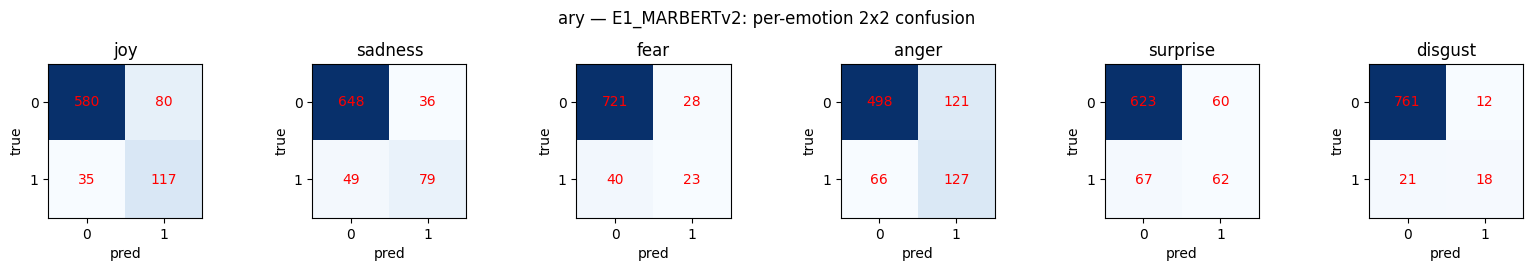

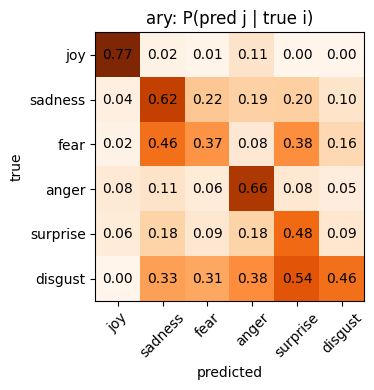

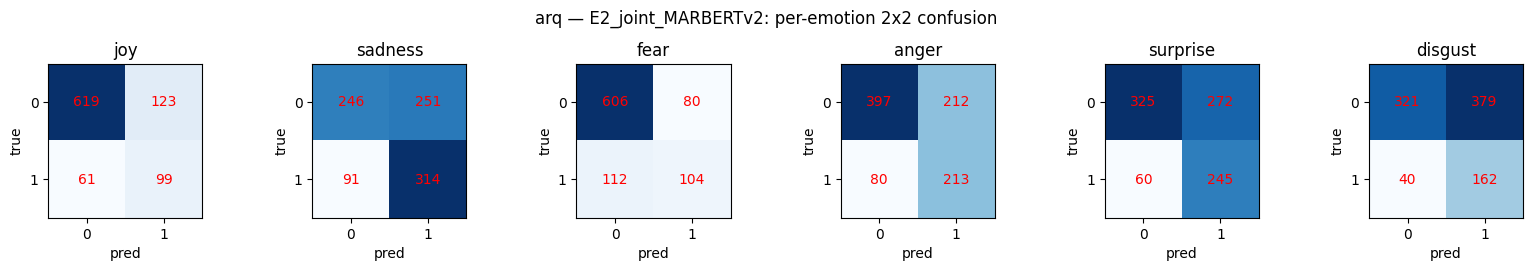

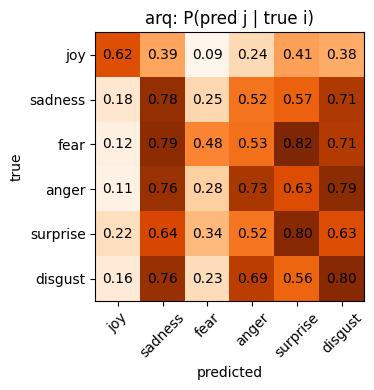

In [47]:
# confusion matrices of the model retained (chosen on val)
for l in LANGS:
    chosen = TOP[l][0]; pv, pt, thr = ens(chosen, l); P = decide(pt, thr); yt = Y(SPLIT[l]["test"])
    cm = multilabel_confusion_matrix(yt, P)
    fig, ax = plt.subplots(1, 6, figsize=(16, 2.6))
    for j, e in enumerate(EMOS):
        ax[j].imshow(cm[j], cmap="Blues"); ax[j].set_title(e); ax[j].set_xticks([0, 1]); ax[j].set_yticks([0, 1])
        ax[j].set_xlabel("pred"); ax[j].set_ylabel("true")
        for a in range(2):
            for b in range(2): ax[j].text(b, a, cm[j][a, b], ha="center", va="center", color="red")
    plt.suptitle(f"{l} — {chosen}: per-emotion 2x2 confusion"); plt.tight_layout(); plt.show()
    # emotion-vs-emotion: of texts truly having emotion i, how often is emotion j predicted
    M = np.array([[(P[yt[:, i] == 1][:, j]).mean() if yt[:, i].sum() else 0 for j in range(6)] for i in range(6)])
    plt.figure(figsize=(4.8, 4)); plt.imshow(M, cmap="Oranges"); plt.xticks(range(6), EMOS, rotation=45); plt.yticks(range(6), EMOS)
    for i in range(6):
        for j in range(6): plt.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center")
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"{l}: P(pred j | true i)"); plt.tight_layout(); plt.show()

### `tests/` — sanity tests of the deliverables
Writes `tests/test_deliverables.py` and runs it. It checks: schema of `results/results.csv`; no test score logged before Part F; one `predictions/<model>_seed<k>.csv` per model/seed with the right columns, sizes (812 ary / 902 arq), unique ids, probabilities in [0, 1], and identical `y_true` across all models.

In [48]:
TESTS_PY = '"""Sanity tests of the deliverables. Run:  python -m pytest tests -q   (from the notebook working directory)."""\nimport os, re, glob\nimport pandas as pd\n\nEMOS = ["joy", "sadness", "fear", "anger", "surprise", "disgust"]\nTEST_SIZE = {"ary": 812, "arq": 902}                 # official test sizes (assignment)\nROOT = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..")\nRES = os.path.join(ROOT, "results", "results.csv")\nPRED_FILES = sorted(glob.glob(os.path.join(ROOT, "predictions", "*_seed*.csv")))\n\n\ndef test_results_csv_schema():\n    df = pd.read_csv(RES)\n    assert {"part", "model", "lang", "split", "macro_f1", "extra"} <= set(df.columns)\n    assert df.macro_f1.between(-1, 1).all()      # F1 in [0,1]; Pearson r (Track B) in [-1,1]\n    assert set(df.lang) <= {"ary", "arq"}\n    assert set(df.split) <= {"val", "test"}\n\n\ndef test_test_set_only_scored_in_part_F():\n    """protocol: before Part F nothing is scored on test; test rows may only come from F / G"""\n    df = pd.read_csv(RES); t = df[df.split == "test"]\n    assert len(t) > 0, "no test result logged (Part F not run?)"\n    assert t.part.str.match(r"^[FG]").all(), t[~t.part.str.match(r"^[FG]")]\n\n\ndef test_predictions_folder_not_empty():\n    assert len(PRED_FILES) > 0\n\n\ndef test_prediction_file_names():\n    for f in PRED_FILES:\n        assert re.fullmatch(r".+_seed\\d+\\.csv", os.path.basename(f)), f\n\n\ndef test_prediction_file_format():\n    cols = (["id", "lang", "seed"] + ["y_true_" + e for e in EMOS] + ["y_pred_" + e for e in EMOS] + ["p_" + e for e in EMOS])\n    for f in PRED_FILES:\n        d = pd.read_csv(f)\n        assert list(d.columns) == cols, f\n        for l, g in d.groupby("lang"):\n            assert len(g) == TEST_SIZE[l], (f, l, len(g))\n            assert g.id.is_unique, (f, l)\n        for e in EMOS:\n            assert set(d["y_true_" + e].unique()) <= {0, 1} and set(d["y_pred_" + e].unique()) <= {0, 1}, f\n            assert d["p_" + e].between(0, 1).all(), f\n\n\ndef test_same_test_labels_for_every_model():\n    ref = {}\n    for f in PRED_FILES:\n        d = pd.read_csv(f)\n        for l, g in d.groupby("lang"):\n            y = g.sort_values("id")[["id"] + ["y_true_" + e for e in EMOS]].reset_index(drop=True)\n            if l in ref: assert ref[l].equals(y), (f, l)\n            else: ref[l] = y\n'
os.makedirs("tests", exist_ok=True)
open("tests/test_deliverables.py", "w", encoding="utf-8").write(TESTS_PY)
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q"], capture_output=True, text=True)
if "No module named pytest" in r.stderr:                       # pytest missing -> run the test functions directly
    import importlib.util
    spec = importlib.util.spec_from_file_location("t", "tests/test_deliverables.py"); t = importlib.util.module_from_spec(spec); spec.loader.exec_module(t)
    for n in [x for x in dir(t) if x.startswith("test_")]: getattr(t, n)(); print("PASSED", n)
else:
    print(r.stdout[-2500:], r.stderr[-800:])

......                                                                   [100%]
6 passed in 1.40s
 


In [49]:
print(pd.read_csv(RES_CSV).tail(15))
print("Saved: results/results.csv, results/final_table.csv, results/errors_to_label.csv, predictions/<model>_seed<k>.csv, tests/test_deliverables.py")

        part                  model lang split  macro_f1  \
85         F     E2_joint_MARBERTv2  ary  test  0.531529   
86         F          E1_DarijaBERT  ary  test  0.504609   
87         F  D2_states_bilstm_attn  ary  test  0.478654   
88         F                 D1_cls  ary  test  0.400496   
89         F     E2_joint_MARBERTv2  arq  test  0.532468   
90         F             A_tfidf_lr  arq  test  0.504319   
91         F  D2_states_bilstm_attn  arq  test  0.503896   
92         F           E1_MARBERTv2  arq  test  0.468641   
93         F    E2_MARBERTv2_lam0.3  arq  test  0.463278   
94  F-trackB    E2_MARBERTv2_lam0.1  arq  test  0.069347   
95  F-trackB    E2_MARBERTv2_lam0.3  arq  test  0.144338   
96  F-trackB    E2_MARBERTv2_lam1.0  arq  test  0.253231   
97  F-trackB    E2_MARBERTv2_lam3.0  arq  test  0.316275   
98         F   F2_MARBERTv2_arq2ary  ary  test  0.213238   
99         F   F2_MARBERTv2_ary2arq  arq  test  0.214197   

                                       